# Proyecto de Minería de Datos — Avance 1
# Patrones de consumo y asociación de productos

**Dataset:** [InstaCart Online Grocery Basket Analysis Dataset](https://www.kaggle.com/datasets/yasserh/instacart-online-grocery-basket-analysis-dataset) 

**Equipo:**  
>Roberto Benitez Zamora (7CM3)  
>Pérez Muñoz Kevin Isaac (7CM4)  
>Lara Franco Montserrat Guadalupe (7CM4)

# 1. Definición del problema y contexto

Los datos generados a partir de transacciones de comercio electrónico contienen información que permite estudiar diferentes características del comportamiento de compra de los usuarios. Entre estos datos pueden encontrarse los productos adquiridos, la frecuencia de los pedidos, el orden en que se agregan los productos al carrito, las categorías de los productos y la recurrencia con la que determinados productos son adquiridos nuevamente.

Sin embargo, la existencia de grandes cantidades de registros no permite identificar directamente los patrones presentes en el comportamiento de compra. Por ello, resulta necesario aplicar técnicas de análisis y minería de datos que permitan transformar los registros históricos en información que pueda ser interpretada y utilizada para identificar relaciones y características relevantes.

Para este proyecto se utilizará el conjunto de datos de **Instacart**, el cual contiene información relacionada con usuarios, pedidos y productos. La estructura del conjunto de datos permite relacionar los pedidos realizados por los usuarios con los productos adquiridos y sus respectivas categorías. Además, incluye variables relacionadas con el comportamiento temporal de las compras y una variable denominada `reordered`, que indica si un producto había sido adquirido previamente por el usuario.

A partir de estas características se plantea analizar el comportamiento de compra desde tres perspectivas complementarias. La primera consiste en identificar relaciones entre productos que aparecen conjuntamente dentro de los pedidos mediante **reglas de asociación**. La segunda busca identificar grupos de usuarios que presenten características de comportamiento de compra similares mediante **técnicas de clustering**. Finalmente, la tercera consiste en analizar los factores relacionados con la recompra de productos mediante **técnicas de clasificación**, utilizando la variable `reordered` como variable objetivo.

De esta manera, el problema general del proyecto consiste en determinar cómo las técnicas de minería de datos pueden utilizarse para identificar patrones de compra, caracterizar diferentes perfiles de usuarios y analizar el comportamiento de recompra a partir de datos históricos de transacciones.

El análisis exploratorio y estadístico realizado previamente permitió identificar que el conjunto de datos contiene información relevante para abordar estas perspectivas. Entre las variables analizadas se encuentran el número de pedidos, el intervalo entre pedidos, el día de la semana en que se realizan las compras y el comportamiento de recompra. En particular, la variable `reordered` permite distinguir entre productos que fueron adquiridos nuevamente y aquellos que no habían sido comprados anteriormente.

## 1.1 Objetivo general

Analizar el comportamiento de compra de los usuarios mediante técnicas de minería de datos aplicadas al conjunto de datos de Instacart, con el propósito de identificar relaciones entre productos, segmentar usuarios de acuerdo con sus características de compra y analizar los factores relacionados con la recompra de productos, mediante el procesamiento y preparación de los datos para las etapas posteriores de análisis y aprendizaje automático.

## 1.2 Objetivos específicos

1. Analizar la estructura y las características del conjunto de datos de Instacart para identificar las variables relevantes relacionadas con usuarios, pedidos y productos.

2. Realizar un análisis estadístico de las variables seleccionadas con el propósito de identificar características y patrones relevantes del comportamiento de compra.

3. Integrar y procesar los datos relacionados con usuarios, pedidos y productos para construir un conjunto de datos preparado para las etapas posteriores de minería de datos.

4. Identificar relaciones frecuentes entre productos adquiridos dentro de un mismo pedido mediante técnicas de reglas de asociación.

5. Identificar grupos de usuarios con comportamientos de compra similares mediante técnicas de clustering.

6. Analizar la relación entre las características del comportamiento de compra y la recompra de productos mediante técnicas de clasificación.

7. Generar una muestra aleatoria de 100 registros del conjunto de datos procesado como evidencia del resultado obtenido durante la etapa de preparación de los datos.

## 1.3 Preguntas de análisis

A partir del problema planteado se establecen las siguientes preguntas que orientarán las etapas posteriores del proyecto:

* **Reglas de asociación:** ¿Qué productos tienden a ser adquiridos conjuntamente dentro de los pedidos?

* **Clustering:** ¿Es posible identificar grupos de usuarios que presenten comportamientos de compra similares a partir de sus características de consumo?

* **Clasificación:** ¿Qué características del comportamiento de compra se encuentran relacionadas con la recompra de un producto?

Estas preguntas permitirán orientar el procesamiento de los datos y la construcción de las estructuras necesarias para aplicar posteriormente las diferentes técnicas de minería de datos.


## 1. Fuente de datos

Para el desarrollo del proyecto se utiliza el dataset **Instacart Online
Grocery Basket Analysis**, disponible en Kaggle.

El conjunto de datos contiene información sobre órdenes de compra realizadas
por usuarios, los productos incluidos en dichas órdenes y la clasificación de
los productos mediante pasillos y departamentos.

El dataset está compuesto por seis archivos CSV:

- `aisles.csv`: contiene los pasillos o categorías de productos.
- `departments.csv`: contiene los departamentos de productos.
- `products.csv`: contiene información de los productos.
- `orders.csv`: contiene información de las órdenes realizadas por los usuarios.
- `order_products__prior.csv`: contiene los productos asociados con órdenes
  anteriores.
- `order_products__train.csv`: contiene los productos asociados con las
  órdenes utilizadas para entrenamiento.

La fuente de datos seleccionada permite relacionar usuarios, órdenes y
productos, lo que proporciona información suficiente para estudiar diferentes
características del comportamiento de compra.

## 2. Carga de los datos

En esta etapa se cargan los archivos CSV utilizando la biblioteca `pandas`.
Cada archivo se almacena en un DataFrame independiente para facilitar su
exploración y posterior integración.

Se conserva la estructura original de los archivos durante esta etapa. Las
transformaciones y procesos de limpieza se realizarán posteriormente, después
de comprender la estructura y calidad de los datos.

In [1]:
# ==========================================
# 1. CARGA DE LOS DATOS
# ==========================================
# Importamos pandas.
# Pandas es la librería que utilizaremos para trabajar con los archivos CSV y manipular nuestros datos.
import pandas as pd
# Importamos os.
# Esta librería permite trabajar con rutas y archivos del sistema operativo. Por ahora no la estamos utilizando directamente, pero nos puede servir posteriormente.
import os

# ------------------------------------------
# RUTA DE LOS ARCHIVOS
# ------------------------------------------
# Guardamos en una variable la ubicación donde
# se encuentran nuestros archivos CSV.
ruta = "../data/raw/Instacard_raw/"

# ------------------------------------------
# CARGA DE LAS TABLAS
# ------------------------------------------
# pd.read_csv() permite leer un archivo CSV y convertirlo en un DataFrame de pandas.
# Un DataFrame es básicamente una tabla formada por filas y columnas.
aisles = pd.read_csv(ruta + "aisles.csv")
departments = pd.read_csv(ruta + "departments.csv")
products = pd.read_csv(ruta + "products.csv")
orders = pd.read_csv(ruta + "orders.csv")
order_products_prior = pd.read_csv(ruta + "order_products__prior.csv")
order_products_train = pd.read_csv(ruta + "order_products__train.csv")

# ------------------------------------------
# MOSTRAR EL TAMAÑO DE CADA TABLA
# ------------------------------------------
# .shape devuelve una tupla:
# (número_de_filas, número_de_columnas)
# Por ejemplo:
# (134, 2)
# significa que la tabla tiene:
# 134 filas
# 2 columnas.
print("Aisles:", aisles.shape)
print("Departments:", departments.shape)
print("Products:", products.shape)
print("Orders:", orders.shape)
print("Order products prior:", order_products_prior.shape)
print("Order products train:", order_products_train.shape)

# Como resultado de estre programa veremos el tamaño de nuestras tablas 

Aisles: (134, 2)
Departments: (21, 2)
Products: (49688, 4)
Orders: (3421083, 7)
Order products prior: (32434489, 4)
Order products train: (1384617, 4)


### Dimensiones de las tablas

La exploración inicial permite identificar que las tablas presentan diferentes
dimensiones. Las tablas `orders` y `order_products__prior` concentran la mayor
cantidad de registros, mientras que `aisles` y `departments` funcionan como
tablas de referencia con un número reducido de registros.

Las dimensiones obtenidas son:

- `aisles`: 134 registros y 2 columnas.
- `departments`: 21 registros y 2 columnas.
- `products`: 49,688 registros y 4 columnas.
- `orders`: 3,421,083 registros y 7 columnas.
- `order_products__prior`: 32,434,489 registros y 4 columnas.
- `order_products__train`: 1,384,617 registros y 4 columnas.

La diferencia en el número de registros muestra que el dataset contiene una
gran cantidad de información transaccional, especialmente en las tablas que
relacionan órdenes con productos.

## 3. Exploración de la estructura de los datos

Para comprender cómo se encuentran organizados los datos, se identificaron
las columnas presentes en cada una de las tablas.

Esta revisión permite reconocer las variables disponibles y establecer las
posibles relaciones entre las tablas mediante sus identificadores.

In [2]:
# ==========================================
# 2. COLUMNAS DE CADA TABLA
# ==========================================

print("COLUMNAS DE AISLES")
print(aisles.columns)
print()

print("COLUMNAS DE DEPARTMENTS")
print(departments.columns)
print()

print("COLUMNAS DE PRODUCTS")
print(products.columns)
print()

print("COLUMNAS DE ORDERS")
print(orders.columns)
print()

print("COLUMNAS DE ORDER_PRODUCTS_PRIOR")
print(order_products_prior.columns)
print()

print("COLUMNAS DE ORDER_PRODUCTS_TRAIN")
print(order_products_train.columns)

COLUMNAS DE AISLES
Index(['aisle_id', 'aisle'], dtype='str')

COLUMNAS DE DEPARTMENTS
Index(['department_id', 'department'], dtype='str')

COLUMNAS DE PRODUCTS
Index(['product_id', 'product_name', 'aisle_id', 'department_id'], dtype='str')

COLUMNAS DE ORDERS
Index(['order_id', 'user_id', 'eval_set', 'order_number', 'order_dow',
       'order_hour_of_day', 'days_since_prior_order'],
      dtype='str')

COLUMNAS DE ORDER_PRODUCTS_PRIOR
Index(['order_id', 'product_id', 'add_to_cart_order', 'reordered'], dtype='str')

COLUMNAS DE ORDER_PRODUCTS_TRAIN
Index(['order_id', 'product_id', 'add_to_cart_order', 'reordered'], dtype='str')


### Relaciones entre las tablas

A partir de las columnas identificadas se observa que las tablas pueden
relacionarse mediante diferentes identificadores.

La tabla `products` relaciona cada producto con un `aisle_id` y un
`department_id`, permitiendo vincular los productos con las tablas
`aisles` y `departments`.

Por otra parte, las tablas `order_products__prior` y
`order_products__train` relacionan las órdenes con los productos mediante
`order_id` y `product_id`.

Finalmente, la tabla `orders` contiene información adicional de cada orden,
como el usuario que la realizó, el número de orden, el día de la semana y la
hora en que fue realizada.

Estas relaciones serán utilizadas posteriormente para integrar la información
y construir el dataset procesado.

In [3]:
# ==========================================
# 3. PRIMEROS REGISTROS DE CADA TABLA
# ==========================================
# head() nos muestra por defecto los primeros 5 registros de cada DataFrame.
# Y display() hace que pandas los muestre como una tabla mucho más legible en Jupyter.

print("AISLES")
display(aisles.head())

print("\nDEPARTMENTS")
display(departments.head())

print("\nPRODUCTS")
display(products.head())

print("\nORDERS")
display(orders.head())

print("\nORDER_PRODUCTS_PRIOR")
display(order_products_prior.head())

print("\nORDER_PRODUCTS_TRAIN")
display(order_products_train.head())

AISLES


,aisle_id,aisle
0,1,prepared soups salads
1,2,specialty cheeses
2,3,energy granola bars
3,4,instant foods
4,5,marinades meat preparation



DEPARTMENTS


,department_id,department
0,1,frozen
1,2,other
2,3,bakery
3,4,produce
4,5,alcohol



PRODUCTS


...

,order_id,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order
0,2539329,1,prior,1,2,8,NaN
1,2398795,1,prior,2,3,7,15.0
2,473747,1,prior,3,3,12,21.0
3,2254736,1,prior,4,4,7,29.0
4,431534,1,prior,5,4,15,28.0



ORDER_PRODUCTS_PRIOR


,order_id,product_id,add_to_cart_order,reordered
0,2,33120,1,1
1,2,28985,2,1
2,2,9327,3,0
3,2,45918,4,1
4,2,30035,5,0



ORDER_PRODUCTS_TRAIN


,order_id,product_id,add_to_cart_order,reordered
0,1,49302,1,1
1,1,11109,2,1
2,1,10246,3,0
3,1,49683,4,0
4,1,43633,5,1


## 4. Análisis de valores faltantes

Como parte de la exploración de la calidad de los datos, se revisó la presencia
de valores nulos en cada una de las tablas.

La identificación de valores faltantes es importante antes de realizar el
análisis estadístico y las transformaciones, ya que es necesario determinar si
estos valores representan errores en los datos o si tienen un significado
dentro del contexto de la información.

In [4]:
# ==========================================
# 4. VALORES FALTANTES
# ==========================================

# isnull() identifica las celdas que contienen
# valores nulos (NaN).
#
# sum() cuenta cuántos valores nulos existen
# en cada columna.
#
# Por lo tanto:
#
# df.isnull().sum()
#
# nos dice cuántos datos faltantes tiene
# cada columna del DataFrame.


print("VALORES NULOS - AISLES")
print(aisles.isnull().sum())
print()

print("VALORES NULOS - DEPARTMENTS")
print(departments.isnull().sum())
print()

print("VALORES NULOS - PRODUCTS")
print(products.isnull().sum())
print()

print("VALORES NULOS - ORDERS")
print(orders.isnull().sum())
print()

print("VALORES NULOS - ORDER_PRODUCTS_PRIOR")
print(order_products_prior.isnull().sum())
print()

print("VALORES NULOS - ORDER_PRODUCTS_TRAIN")
print(order_products_train.isnull().sum())

VALORES NULOS - AISLES
aisle_id    0
aisle       0
dtype: int64

VALORES NULOS - DEPARTMENTS
department_id    0
department       0
dtype: int64

VALORES NULOS - PRODUCTS
product_id       0
product_name     0
aisle_id         0
department_id    0
dtype: int64

VALORES NULOS - ORDERS
order_id                       0
user_id                        0
eval_set                       0
order_number                   0
order_dow                      0
order_hour_of_day              0
days_since_prior_order    206209
dtype: int64

VALORES NULOS - ORDER_PRODUCTS_PRIOR
order_id             0
product_id           0
add_to_cart_order    0
reordered            0
dtype: int64

VALORES NULOS - ORDER_PRODUCTS_TRAIN
order_id             0
product_id           0
add_to_cart_order    0
reordered            0
dtype: int64


In [5]:
# ==========================================
# 5. ANALIZAR LOS VALORES NULOS
#    EN days_since_prior_order
# ==========================================

# Contamos cuántos registros tienen un valor nulo
# en la columna days_since_prior_order.
#
# isnull() devuelve True cuando encuentra un NaN.
# sum() cuenta cuántos True existen.

nulos_dias = orders["days_since_prior_order"].isnull().sum()

print("Número de valores nulos:", nulos_dias)


# ------------------------------------------
# COMPROBAR SI LOS NULOS CORRESPONDEN
# A LA PRIMERA ORDEN DE CADA USUARIO
# ------------------------------------------

# Filtramos únicamente las filas donde
# days_since_prior_order es nulo.

ordenes_sin_anterior = orders[
    orders["days_since_prior_order"].isnull()
]


# Mostramos las primeras filas para observar
# qué valor tiene order_number.

display(
    ordenes_sin_anterior[
        ["user_id", "order_number", "days_since_prior_order"]
    ].head(10)
)

Número de valores nulos: 206209


,user_id,order_number,days_since_prior_order
0,1,1,NaN
11,2,1,NaN
26,3,1,NaN
39,4,1,NaN
45,5,1,NaN
50,6,1,NaN
54,7,1,NaN
75,8,1,NaN
79,9,1,NaN
83,10,1,NaN


### Hallazgos sobre valores faltantes

Las tablas `aisles`, `departments`, `products`,
`order_products__prior` y `order_products__train` no presentan valores
nulos en las columnas analizadas.

En la tabla `orders` se identificaron 206,209 valores nulos en la variable
`days_since_prior_order`.

Al analizar estos registros se observó que corresponden a órdenes cuyo
`order_number` es igual a 1. Esto indica que se trata de la primera orden
registrada de dichos usuarios, por lo que no existe una orden anterior con la
cual calcular el número de días transcurridos.

Por esta razón, estos valores nulos no se consideran automáticamente errores
de captura y se conservarán durante la etapa de exploración. La estrategia
definitiva para su tratamiento se determinará posteriormente, dependiendo del
uso que se haga de esta variable en el dataset final.

## 5. Tipos de datos

En esta etapa se identifican los tipos de datos almacenados en cada columna
de las tablas.

Conocer el tipo de dato de cada variable es importante para determinar qué
operaciones y análisis pueden realizarse posteriormente. Por ejemplo, las
variables numéricas pueden utilizarse para obtener medidas estadísticas,
mientras que las variables de texto pueden utilizarse para realizar análisis
categóricos o descriptivos.

También se identifican variables que, aunque están almacenadas como números,
representan categorías o identificadores. Esta distinción será importante
durante las etapas posteriores de procesamiento y preparación del dataset.

In [6]:
# ==========================================
# 6. TIPOS DE DATOS
# ==========================================

# dtypes nos permite conocer el tipo de dato
# almacenado en cada columna del DataFrame.
#
# Algunos tipos que podemos encontrar:
#
# int64   → números enteros
# float64 → números decimales
# object  → texto/cadenas de caracteres
#
# Conocer los tipos de datos será importante
# para determinar qué análisis estadísticos
# podremos realizar posteriormente.


print("TIPOS DE DATOS - AISLES")
print(aisles.dtypes)
print()

print("TIPOS DE DATOS - DEPARTMENTS")
print(departments.dtypes)
print()

print("TIPOS DE DATOS - PRODUCTS")
print(products.dtypes)
print()

print("TIPOS DE DATOS - ORDERS")
print(orders.dtypes)
print()

print("TIPOS DE DATOS - ORDER_PRODUCTS_PRIOR")
print(order_products_prior.dtypes)
print()

print("TIPOS DE DATOS - ORDER_PRODUCTS_TRAIN")
print(order_products_train.dtypes)

TIPOS DE DATOS - AISLES
aisle_id    int64
aisle         str
dtype: object

TIPOS DE DATOS - DEPARTMENTS
department_id    int64
department         str
dtype: object

TIPOS DE DATOS - PRODUCTS
product_id       int64
product_name       str
aisle_id         int64
department_id    int64
dtype: object

TIPOS DE DATOS - ORDERS
order_id                    int64
user_id                     int64
eval_set                      str
order_number                int64
order_dow                   int64
order_hour_of_day           int64
days_since_prior_order    float64
dtype: object

TIPOS DE DATOS - ORDER_PRODUCTS_PRIOR
order_id             int64
product_id           int64
add_to_cart_order    int64
reordered            int64
dtype: object

TIPOS DE DATOS - ORDER_PRODUCTS_TRAIN
order_id             int64
product_id           int64
add_to_cart_order    int64
reordered            int64
dtype: object


### Interpretación de los tipos de datos

La mayoría de las variables identificadoras y numéricas se encuentran
almacenadas como enteros (`int64`). Entre ellas se encuentran identificadores
como `product_id`, `order_id`, `user_id`, `aisle_id` y `department_id`.

Sin embargo, que una variable esté almacenada como entero no significa
necesariamente que sea una variable numérica para efectos estadísticos. Por
ejemplo, `product_id` identifica un producto y no representa una cantidad que
tenga sentido promediar.

La variable `product_name`, así como `aisle`, `department` y `eval_set`, se
encuentran almacenadas como cadenas de texto (`str`) y serán tratadas como
variables categóricas o descriptivas.

Dentro de la tabla `orders`, las variables `order_number`,
`order_dow` y `order_hour_of_day` se encuentran almacenadas como enteros.
Estas variables requieren una interpretación específica: `order_number`
representa el número de orden del usuario, mientras que `order_dow` y
`order_hour_of_day` representan características temporales codificadas
numéricamente.

La variable `days_since_prior_order` se encuentra almacenada como
`float64`, debido principalmente a que contiene valores nulos. Aunque
representa una cantidad numérica de días, sus valores faltantes deberán ser
considerados durante la etapa de procesamiento.

Finalmente, las variables `add_to_cart_order` y `reordered` son enteras.
`add_to_cart_order` representa la posición en la que un producto fue agregado
al carrito, mientras que `reordered` es una variable binaria que indica si el
producto había sido comprado anteriormente por el usuario.

## 5.1 Diccionario de datos

El diccionario de datos describe la estructura y el significado de las
variables que componen el conjunto de datos utilizado en el proyecto.

Hay que distinguir dos cosas:

Tipo de dato: cómo está almacenado en Python (int64, str, float64).
Tipo de variable: qué representa conceptualmente (identificador, categórica, numérica, binaria, etc.).

Por ejemplo:
```
product_id
    ↓
int64                  ← tipo de almacenamiento
    ↓
Identificador          ← significado
    ↓
No es una variable     ← no debemos calcularle una media
estadística
```

Para cada variable se identifica la tabla a la que pertenece, su nombre,
tipo de dato, significado y, cuando corresponde, los valores o categorías
que puede representar.

Esta descripción permite comprender correctamente los datos antes de realizar
el análisis estadístico y evita interpretar como variables cuantitativas
aquellos campos que funcionan únicamente como identificadores o códigos.

Además, el diccionario facilita la identificación de las relaciones entre las
diferentes tablas que componen el dataset.

### Tabla `aisles`

La tabla `aisles` contiene el catálogo de pasillos o categorías específicas
en las que se clasifican los productos.

| Columna    | Tipo de dato | Tipo de variable | Descripción                                  |
| ---------- | ------------ | ---------------- | -------------------------------------------- |
| `aisle_id` | `int64`      | Identificador    | Identificador único del pasillo.             |
| `aisle`    | `str`        | Categórica       | Nombre del pasillo o categoría del producto. |


### Tabla `departments`

La tabla `departments` contiene los departamentos generales utilizados para
clasificar los productos.


| Columna         | Tipo de dato | Tipo de variable | Descripción                                           |
| --------------- | ------------ | ---------------- | ----------------------------------------------------- |
| `department_id` | `int64`      | Identificador    | Identificador del departamento.                       |
| `department`    | `str`        | Categórica       | Nombre del departamento al que pertenece el producto. |


### Tabla `products`

La tabla `products` contiene el catálogo de productos disponibles en el
dataset y permite relacionar cada producto con su pasillo y departamento.

| Columna         | Tipo de dato | Tipo de variable | Descripción                                                  |
| --------------- | ------------ | ---------------- | ------------------------------------------------------------ |
| `product_id`    | `int64`      | Identificador    | Identificador único del producto.                            |
| `product_name`  | `str`        | Categórica/texto | Nombre del producto.                                         |
| `aisle_id`      | `int64`      | Clave foránea    | Identificador del pasillo al que pertenece el producto.      |
| `department_id` | `int64`      | Clave foránea    | Identificador del departamento al que pertenece el producto. |


Aquí aparecen nuestras primeras relaciones:
```
products.aisle_id
       ↓
aisles.aisle_id
```
y:
```
products.department_id
       ↓
departments.department_id
```
Por eso aisle_id y department_id son más que simples números: funcionan como claves para relacionar tablas.

### Tabla `orders`

La tabla `orders` contiene información sobre las órdenes realizadas por los
usuarios. Incluye información relacionada con el usuario, el número de orden,
el día y la hora en que se realizó, así como el tiempo transcurrido desde la
orden anterior cuando existe.

| Columna                  | Tipo de dato | Tipo de variable           | Descripción                                                                                                           |
| ------------------------ | ------------ | -------------------------- | --------------------------------------------------------------------------------------------------------------------- |
| `order_id`               | `int64`      | Identificador              | Identificador único de la orden.                                                                                      |
| `user_id`                | `int64`      | Identificador              | Identificador del usuario que realizó la orden.                                                                       |
| `eval_set`               | `str`        | Categórica                 | Conjunto al que pertenece la orden dentro de la estructura del dataset.                                               |
| `order_number`           | `int64`      | Numérica discreta          | Número secuencial de la orden para el usuario.                                                                        |
| `order_dow`              | `int64`      | Categórica codificada      | Día de la semana en que se realizó la orden, codificado de 0 a 6.                                                     |
| `order_hour_of_day`      | `int64`      | Temporal discreta          | Hora del día en que se realizó la orden, de 0 a 23.                                                                   |
| `days_since_prior_order` | `float64`    | Numérica continua/discreta | Número de días transcurridos desde la orden anterior. Puede contener valores nulos para la primera orden del usuario. |


Aquí tenemos dos variables que tendremos que tratar con especial cuidado:

order_dow
```
0 → Domingo
1 → Lunes
2 → Martes
3 → Miércoles
4 → Jueves
5 → Viernes
6 → Sábado
```
order_hour_of_day
```
0  → 00:00
1  → 01:00
2  → 02:00
...
23 → 23:00
```

### Tabla `order_products__prior`

La tabla `order_products__prior` contiene los productos incluidos en las
órdenes anteriores de los usuarios. Permite relacionar una orden con los
productos que fueron incluidos en ella y conocer el orden en que fueron
agregados al carrito y si fueron productos previamente comprados.

| Columna             | Tipo de dato | Tipo de variable  | Descripción                                                             |
| ------------------- | ------------ | ----------------- | ----------------------------------------------------------------------- |
| `order_id`          | `int64`      | Clave foránea     | Identificador de la orden.                                              |
| `product_id`        | `int64`      | Clave foránea     | Identificador del producto incluido en la orden.                        |
| `add_to_cart_order` | `int64`      | Numérica discreta | Posición en la que el producto fue agregado al carrito.                 |
| `reordered`         | `int64`      | Binaria           | Indica si el producto había sido comprado anteriormente por el usuario. |

Aquí aparece una variable que será muy interesante para nuestro proyecto:

reordered

con valores:
```
0 → No había sido comprado anteriormente
1 → Sí había sido comprado anteriormente
```
Esto posteriormente nos permitirá estudiar el comportamiento de recompra.

### Tabla `order_products__train`

La tabla `order_products__train` contiene los productos asociados con las
órdenes pertenecientes al conjunto utilizado como datos de entrenamiento
dentro de la estructura original del dataset.

| Columna             | Tipo de dato | Tipo de variable  | Descripción                                                             |
| ------------------- | ------------ | ----------------- | ----------------------------------------------------------------------- |
| `order_id`          | `int64`      | Clave foránea     | Identificador de la orden.                                              |
| `product_id`        | `int64`      | Clave foránea     | Identificador del producto incluido en la orden.                        |
| `add_to_cart_order` | `int64`      | Numérica discreta | Posición en la que el producto fue agregado al carrito.                 |
| `reordered`         | `int64`      | Binaria           | Indica si el producto había sido comprado anteriormente por el usuario. |


## 5.2 Relaciones entre las tablas

Las tablas que componen el dataset de Instacart no deben analizarse
únicamente de manera independiente. Una parte importante de la información
se encuentra distribuida entre diferentes tablas, por lo que es necesario
identificar las claves que permiten relacionarlas.

Las principales relaciones se establecen mediante los identificadores
`order_id`, `product_id`, `aisle_id` y `department_id`.

Estas relaciones permitirán posteriormente integrar la información de las
órdenes, productos, pasillos y departamentos para construir un dataset
consolidado.


### Relación entre `products` y `aisles`

La tabla `products` contiene la columna `aisle_id`, que permite identificar
el pasillo al que pertenece cada producto.

Esta columna puede relacionarse con `aisles.aisle_id`.

La relación puede representarse como:

`products.aisle_id → aisles.aisle_id`

De esta manera, a partir de un producto podemos conocer el nombre del
pasillo al que pertenece.

```
products
┌──────────────┐
│ product_id   │
│ product_name │
│ aisle_id ────┼──────┐
│ department_id│      │
└──────────────┘      ↓
                 aisles
                 ┌──────────┐
                 │ aisle_id │
                 │ aisle    │
                 └──────────┘
```

### Relación entre `products` y `departments`

La tabla `products` también contiene la columna `department_id`, que permite
identificar el departamento al que pertenece cada producto.

Esta columna puede relacionarse con `departments.department_id`.

La relación puede representarse como:

`products.department_id → departments.department_id`

Esta relación permite obtener el nombre del departamento correspondiente a
cada producto.

### Relación entre `orders` y `order_products__prior`

La tabla `orders` contiene información general sobre cada orden, mientras
que `order_products__prior` contiene los productos incluidos en esas órdenes.

Ambas tablas pueden relacionarse mediante la columna `order_id`:

`orders.order_id → order_products__prior.order_id`

Esta relación permite pasar de la información general de una orden a los
productos que fueron incluidos en ella.
```
orders
┌──────────────┐
│ order_id ────┼─────────┐
│ user_id      │         │
│ order_number │         ↓
│ order_dow    │   order_products__prior
│ ...          │   ┌──────────────┐
└──────────────┘   │ order_id     │
                   │ product_id   │
                   │ reordered    │
                   └──────────────┘
```
### Relación entre órdenes y productos

La tabla `order_products__prior` contiene tanto `order_id` como
`product_id`. Por lo tanto, puede utilizarse como vínculo entre las órdenes
y el catálogo de productos.

La relación con `products` se establece mediante:

`order_products__prior.product_id → products.product_id`

Esto permite conocer qué producto corresponde a cada registro de una orden.

```
orders
   │
   │ order_id
   ↓
order_products__prior
   │
   │ product_id
   ↓
products
   │
   ├──────────→ aisles
   │
   └──────────→ departments
```

### Verificación de las claves de relación

Antes de integrar las tablas, se verificará que las columnas utilizadas como
claves de relación permitan encontrar correspondencias entre las diferentes
tablas.

Esta comprobación es importante para detectar posibles identificadores que
no tengan correspondencia en la tabla relacionada.

In [7]:
# ==========================================
# 5.2.5 VERIFICACIÓN DE RELACIONES
# ==========================================

# ------------------------------------------
# RELACIÓN PRODUCTS → AISLES
# ------------------------------------------

# Verificamos cuántos aisle_id de products
# también existen en la tabla aisles.

aisles_validos = products["aisle_id"].isin(
    aisles["aisle_id"]
)


# sum() cuenta cuántos valores son True.
# Es decir, cuántos productos tienen un
# aisle_id que existe en la tabla aisles.

print(
    "Productos con aisle_id válido:",
    aisles_validos.sum()
)

print(
    "Productos con aisle_id sin correspondencia:",
    (~aisles_validos).sum()
)


# ------------------------------------------
# RELACIÓN PRODUCTS → DEPARTMENTS
# ------------------------------------------

# Verificamos cuántos department_id de
# products existen en departments.

departments_validos = products["department_id"].isin(
    departments["department_id"]
)


print(
    "\nProductos con department_id válido:",
    departments_validos.sum()
)

print(
    "Productos con department_id sin correspondencia:",
    (~departments_validos).sum()
)


# ------------------------------------------
# RELACIÓN ORDER_PRODUCTS → PRODUCTS
# ------------------------------------------

# Verificamos que los product_id utilizados
# en order_products__prior existan en products.

productos_en_prior = order_products_prior["product_id"].isin(
    products["product_id"]
)


print(
    "\nRegistros de prior con product_id válido:",
    productos_en_prior.sum()
)

print(
    "Registros de prior con product_id sin correspondencia:",
    (~productos_en_prior).sum()
)

# ==========================================
# RELACIÓN ORDER_PRODUCTS → ORDERS
# ==========================================

# Verificamos que cada order_id presente
# en order_products_prior exista también
# en la tabla orders.

ordenes_validas = order_products_prior["order_id"].isin(
    orders["order_id"]
)


# Contamos cuántos registros tienen un
# order_id que sí existe en orders.

print(
    "Registros de prior con order_id válido:",
    ordenes_validas.sum()
)


# Contamos cuántos registros tienen un
# order_id que NO existe en orders.

print(
    "Registros de prior con order_id sin correspondencia:",
    (~ordenes_validas).sum()
)

Productos con aisle_id válido: 49688
Productos con aisle_id sin correspondencia: 0

Productos con department_id válido: 49688
Productos con department_id sin correspondencia: 0

Registros de prior con product_id válido: 32434489
Registros de prior con product_id sin correspondencia: 0
Registros de prior con order_id válido: 32434489
Registros de prior con order_id sin correspondencia: 0


### Resultado de la verificación de las relaciones

La verificación de las claves de relación muestra que existe correspondencia
completa entre las tablas analizadas.

Los **49,688 productos** presentan un `aisle_id` válido que puede encontrarse
en la tabla `aisles`, y los **49,688 productos** presentan un `department_id`
válido que puede encontrarse en la tabla `departments`.

Además, los **32,434,489 registros** de `order_products__prior` presentan un
`product_id` con correspondencia en la tabla `products`.

No se encontraron identificadores sin correspondencia en ninguna de las
relaciones verificadas.

Por lo tanto, estas relaciones pueden utilizarse posteriormente durante la
integración de los datos.

## 6. Análisis estadístico

El análisis estadístico tiene como objetivo describir las características
principales de los datos y detectar patrones relevantes en el comportamiento
de las órdenes.

Para evitar interpretaciones incorrectas, no todas las variables numéricas
serán consideradas variables estadísticas. Los identificadores como
`order_id` y `user_id` se utilizarán para relacionar registros, pero no se
considerarán variables cuantitativas para calcular medidas como la media o la
desviación estándar.

Inicialmente se analizarán las variables relacionadas con las características
de las órdenes, como el número de orden, el día de la semana, la hora de
realización y el tiempo transcurrido desde la orden anterior.

In [8]:
# ==========================================
# 6.1 ESTADÍSTICA DESCRIPTIVA DE ORDERS
# ==========================================

# Seleccionamos únicamente las variables que
# representan características cuantitativas o
# temporales de las órdenes.
#
# No incluimos:
# - order_id
# - user_id
#
# porque son identificadores y no cantidades
# que tengan una interpretación estadística
# directa.

variables_orders = [
    "order_number",
    "order_dow",
    "order_hour_of_day",
    "days_since_prior_order"
]


# describe() calcula estadísticas descriptivas
# para las variables seleccionadas.
#
# Entre otras medidas obtenemos:
#
# count  -> cantidad de valores disponibles
# mean   -> promedio
# std    -> desviación estándar
# min    -> valor mínimo
# 25%    -> primer cuartil
# 50%    -> mediana
# 75%    -> tercer cuartil
# max    -> valor máximo

estadisticas_orders = orders[variables_orders].describe()


# Mostramos la tabla de estadísticas.

display(estadisticas_orders)

,order_number,order_dow,order_hour_of_day,days_since_prior_order
count,3.421083e+06,3.421083e+06,3.421083e+06,3.214874e+06
mean,1.715486e+01,2.776219e+00,1.345202e+01,1.111484e+01
std,1.773316e+01,2.046829e+00,4.226088e+00,9.206737e+00
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,5.000000e+00,1.000000e+00,1.000000e+01,4.000000e+00
50%,1.100000e+01,3.000000e+00,1.300000e+01,7.000000e+00
75%,2.300000e+01,5.000000e+00,1.600000e+01,1.500000e+01
max,1.000000e+02,6.000000e+00,2.300000e+01,3.000000e+01


### Interpretación de la estadística descriptiva

La estadística descriptiva permite identificar algunas características
generales de las órdenes registradas en el dataset.

La variable `order_number` presenta un valor mínimo de 1 y un máximo de 100.
Su media es aproximadamente 17.15, mientras que la mediana es 11. Esta
diferencia indica que existen usuarios con un número considerablemente mayor
de órdenes, lo que incrementa el promedio.

La variable `order_dow` presenta valores entre 0 y 6, correspondientes a los
días de la semana. Debido a que estos valores representan categorías
codificadas y no cantidades continuas, la media no se utilizará para
interpretar el día promedio de compra. En su lugar, se analizará la frecuencia
de órdenes para cada día de la semana.

La variable `order_hour_of_day` presenta valores entre 0 y 23, con una media
aproximada de 13.45 y una mediana de 13. Esto proporciona una primera
referencia sobre el horario de las órdenes, aunque será necesario analizar la
distribución de frecuencias para identificar las horas con mayor concentración
de pedidos.

Por último, `days_since_prior_order` presenta una media aproximada de 11.11
días y una mediana de 7 días. La diferencia entre ambas medidas sugiere que
existen intervalos de tiempo relativamente largos que influyen en el promedio.
Esta variable contiene valores nulos correspondientes a las primeras órdenes
de los usuarios, por lo que el número de observaciones disponibles para su
cálculo estadístico es menor que el de las demás variables.

### 6.2 Distribución de órdenes por día de la semana

La variable `order_dow` representa el día de la semana en que se realizó una
orden. Sus valores van de 0 a 6.

Debido a que esta variable representa categorías codificadas numéricamente,
se utilizará un análisis de frecuencias en lugar de interpretar directamente
su media.

Se contará el número de órdenes realizadas en cada día para identificar los
días con mayor y menor actividad dentro del conjunto de datos.

In [9]:
# ==========================================
# 6.2 ÓRDENES POR DÍA DE LA SEMANA
# ==========================================

# value_counts() cuenta cuántas veces aparece
# cada valor dentro de una columna.
#
# En este caso queremos saber cuántas órdenes
# corresponden a cada día de la semana.

ordenes_por_dia = orders["order_dow"].value_counts()


# sort_index() ordena el resultado utilizando
# el índice de la serie.
#
# Esto hace que los días aparezcan en orden:
# 0, 1, 2, 3, 4, 5, 6
#
# en lugar de aparecer ordenados de mayor
# a menor frecuencia.

ordenes_por_dia = ordenes_por_dia.sort_index()


# Mostramos el resultado.

display(ordenes_por_dia)

order_dow
0    600905
1    587478
2    467260
3    436972
4    426339
5    453368
6    448761
Name: count, dtype: int64

### Proporción de órdenes por día

Además del número absoluto de órdenes, se calculará la proporción que
representa cada día respecto al total de órdenes.

El porcentaje permitirá comparar la participación de cada día de la semana
independientemente del tamaño total del conjunto de datos.

In [10]:
# ==========================================
# 6.2.1 PORCENTAJE DE ÓRDENES POR DÍA
# ==========================================

# Sumamos todas las órdenes para obtener
# el total de registros analizados.

total_ordenes = ordenes_por_dia.sum()


# Dividimos las órdenes de cada día entre
# el total de órdenes.
#
# Multiplicamos por 100 para convertir
# la proporción en porcentaje.

porcentaje_por_dia = (
    ordenes_por_dia / total_ordenes
) * 100


# Redondeamos los porcentajes a dos
# decimales para facilitar su lectura.

porcentaje_por_dia = porcentaje_por_dia.round(2)


# Mostramos el resultado.

display(porcentaje_por_dia)

order_dow
0    17.56
1    17.17
2    13.66
3    12.77
4    12.46
5    13.25
6    13.12
Name: count, dtype: float64

### Visualización de la distribución semanal

Para facilitar la interpretación de la distribución de las órdenes, se
generará una gráfica de barras que muestre el porcentaje de órdenes
correspondiente a cada día de la semana.

Esta visualización permitirá identificar de manera más clara las diferencias
en la actividad de compra entre los distintos días.

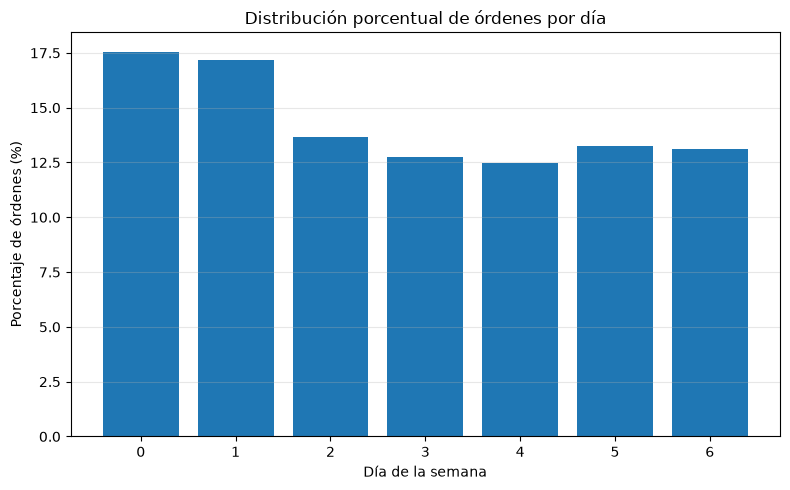

In [11]:
# ==========================================
# 6.2.2 GRÁFICA DE ÓRDENES POR DÍA
# ==========================================

import matplotlib.pyplot as plt


# Creamos una figura para la gráfica.
#
# figsize define el tamaño de la figura:
# 8 pulgadas de ancho × 5 pulgadas de alto.

plt.figure(figsize=(8, 5))


# Creamos una gráfica de barras.
#
# - index contiene los días: 0, 1, 2, ..., 6
# - porcentaje_por_dia contiene el porcentaje
#   correspondiente a cada día.

plt.bar(
    porcentaje_por_dia.index,
    porcentaje_por_dia.values
)


# Agregamos un título para explicar
# qué representa la gráfica.

plt.title("Distribución porcentual de órdenes por día")


# Etiqueta del eje X.

plt.xlabel("Día de la semana")


# Etiqueta del eje Y.

plt.ylabel("Porcentaje de órdenes (%)")


# Definimos explícitamente las posiciones
# de los días para que aparezcan del 0 al 6.

plt.xticks(range(7))


# Agregamos una cuadrícula horizontal
# para facilitar la comparación visual
# de los porcentajes.

plt.grid(axis="y", alpha=0.3)


# Ajustamos automáticamente los espacios
# de la gráfica para evitar que los elementos
# queden cortados.

plt.tight_layout()


# Finalmente mostramos la gráfica.

plt.show()

### Hallazgos: distribución de órdenes por día

La distribución de las órdenes muestra diferencias en la actividad de compra
a lo largo de los siete días de la semana.

El día codificado como `0` presenta la mayor proporción de órdenes, con
**17.56%** del total, seguido por el día `1`, con **17.17%**. En conjunto,
estos dos días concentran aproximadamente **34.73%** de todas las órdenes
registradas.

Por otro lado, el día `4` presenta la menor proporción, con **12.46%** de
las órdenes. Los demás días presentan proporciones relativamente cercanas,
entre **12.77% y 13.66%**.

Estos resultados muestran que la actividad de compra no se distribuye de
manera completamente uniforme durante la semana. Sin embargo, para interpretar
los días como lunes, martes, etc., es necesario consultar la codificación
utilizada por la fuente de datos antes de asignarles nombres específicos.

## 6.3 Distribución temporal de las órdenes

La variable `order_hour_of_day` representa la hora del día en la que se
realizó cada orden. Sus valores van de 0 a 23, donde cada valor corresponde
a una hora del día.

Esta variable permite analizar cómo se distribuye la actividad de compra
a lo largo del día e identificar los periodos horarios en los que se
concentra una mayor cantidad de órdenes.

A diferencia de `order_dow`, esta variable no requiere una conversión de
códigos a nombres de categorías, ya que sus valores corresponden directamente
a las horas del día.

In [12]:
# ==========================================
# 6.3.1 ÓRDENES POR HORA DEL DÍA
# ==========================================

# Contamos cuántas órdenes fueron realizadas
# durante cada hora del día.

ordenes_por_hora = orders["order_hour_of_day"].value_counts()


# Ordenamos las horas de forma ascendente.
#
# Esto permite visualizar el resultado desde
# las 00:00 hasta las 23:00.

ordenes_por_hora = ordenes_por_hora.sort_index()


# Mostramos la cantidad de órdenes
# correspondiente a cada hora.

display(ordenes_por_hora)

order_hour_of_day
0      22758
1      12398
2       7539
3       5474
4       5527
5       9569
6      30529
7      91868
8     178201
9     257812
10    288418
11    284728
12    272841
13    277999
14    283042
15    283639
16    272553
17    228795
18    182912
19    140569
20    104292
21     78109
22     61468
23     40043
Name: count, dtype: int64

### Porcentaje de órdenes por hora

Para facilitar la comparación entre las diferentes horas, se calculará el
porcentaje que representa cada hora respecto al total de órdenes.

El porcentaje permitirá identificar qué horas concentran una mayor
proporción de la actividad de compra.

In [13]:
# ==========================================
# 6.2.2 PORCENTAJE DE ÓRDENES POR HORA
# ==========================================

# Calculamos el número total de órdenes
# sumando las frecuencias de todas las horas.

total_ordenes = ordenes_por_hora.sum()


# Dividimos las órdenes de cada hora
# entre el total de órdenes.
#
# Multiplicamos por 100 para obtener
# el porcentaje.

porcentaje_por_hora = (
    ordenes_por_hora / total_ordenes
) * 100


# Redondeamos los resultados a dos
# decimales para facilitar su lectura.

porcentaje_por_hora = porcentaje_por_hora.round(2)


# Mostramos los porcentajes.

display(porcentaje_por_hora)

order_hour_of_day
0     0.67
1     0.36
2     0.22
3     0.16
4     0.16
5     0.28
6     0.89
7     2.69
8     5.21
9     7.54
10    8.43
11    8.32
12    7.98
13    8.13
14    8.27
15    8.29
16    7.97
17    6.69
18    5.35
19    4.11
20    3.05
21    2.28
22    1.80
23    1.17
Name: count, dtype: float64

### Visualización de la distribución horaria

Se utilizará una gráfica de barras para visualizar la proporción de órdenes
correspondiente a cada hora del día.

La representación permitirá identificar visualmente los periodos de mayor y
menor actividad.

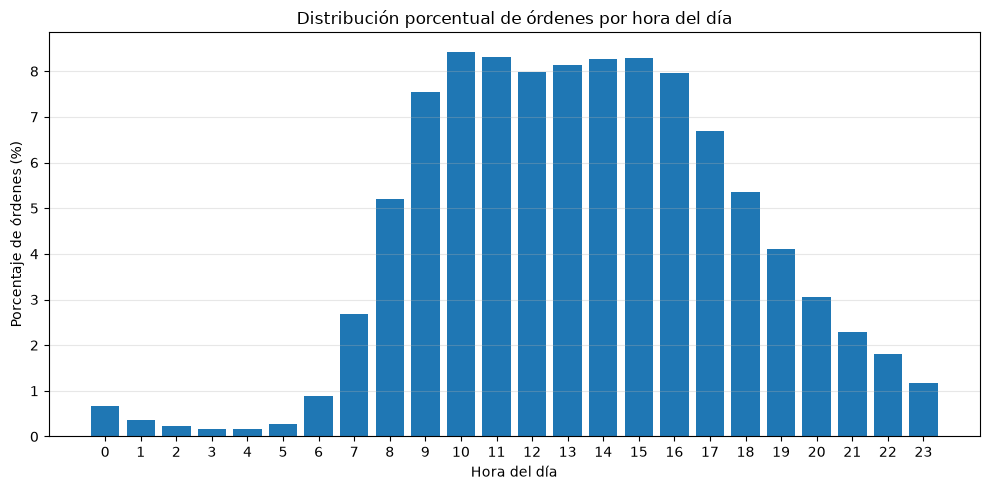

In [14]:
# ==========================================
# 6.2.3 GRÁFICA DE ÓRDENES POR HORA
# ==========================================

import matplotlib.pyplot as plt


# Creamos una figura de 10 pulgadas de ancho
# por 5 pulgadas de alto.

plt.figure(figsize=(10, 5))


# Creamos una barra para cada hora del día.
#
# El eje X contiene las horas 0-23.
# El eje Y contiene el porcentaje de órdenes.

plt.bar(
    porcentaje_por_hora.index,
    porcentaje_por_hora.values
)


# Agregamos el título de la gráfica.

plt.title("Distribución porcentual de órdenes por hora del día")


# Etiqueta del eje X.

plt.xlabel("Hora del día")


# Etiqueta del eje Y.

plt.ylabel("Porcentaje de órdenes (%)")


# Nos aseguramos de mostrar todas las horas
# de 0 a 23 en el eje X.

plt.xticks(range(24))


# Agregamos una cuadrícula horizontal
# para facilitar la comparación de valores.

plt.grid(axis="y", alpha=0.3)


# Ajustamos automáticamente los espacios.

plt.tight_layout()


# Mostramos la gráfica.

plt.show()

### Hallazgos: distribución de órdenes por hora

La distribución de las órdenes presenta un comportamiento claramente
diferenciado a lo largo del día.

La mayor proporción de órdenes se registra a las **10:00 horas**, con
**8.43%** del total. Sin embargo, la actividad no se concentra únicamente
en esta hora, sino que se mantiene elevada durante un periodo amplio del día.

Entre las **9:00 y las 16:00 horas** se concentra aproximadamente el
**64.93% de todas las órdenes**. Dentro de este intervalo, los porcentajes
individuales se mantienen relativamente cercanos, entre aproximadamente
7.54% y 8.43%.

Por el contrario, durante la madrugada se observa una actividad
considerablemente menor. Entre las 2:00 y las 5:00 horas, cada hora
representa menos del 0.30% de las órdenes.

Después de las 16:00 horas se observa una disminución progresiva de la
actividad, alcanzando 1.17% a las 23:00 horas.

En conjunto, los resultados muestran que las órdenes se concentran
principalmente durante las horas diurnas y presentan una actividad mucho
menor durante la madrugada.

## 6.4 Días desde la orden anterior

La variable `days_since_prior_order` representa el número de días
transcurridos desde la orden anterior realizada por el mismo usuario.

Esta variable puede contener valores nulos. Los valores nulos se presentan
principalmente en la primera orden registrada de cada usuario, debido a que
no existe una orden anterior con la cual calcular el intervalo.

Por esta razón, los valores nulos no se consideran automáticamente como
errores o datos faltantes que deban eliminarse. Antes de realizar el análisis
se revisará su frecuencia y posteriormente se analizarán los valores
disponibles.

In [15]:
# ==========================================
# 6.3.1 VALORES NULOS EN DAYS_SINCE_PRIOR_ORDER
# ==========================================

# Contamos cuántos registros tienen un valor
# nulo en days_since_prior_order.

nulos_dias = orders["days_since_prior_order"].isna().sum()


# Obtenemos el número total de órdenes.

total_ordenes = len(orders)


# Calculamos qué porcentaje de las órdenes
# corresponde a registros con valor nulo.

porcentaje_nulos = (
    nulos_dias / total_ordenes
) * 100


# Mostramos los resultados.

print("Valores nulos:", nulos_dias)

print("Total de órdenes:", total_ordenes)

print(
    "Porcentaje de valores nulos:",
    round(porcentaje_nulos, 2),
    "%"
)

Valores nulos: 206209
Total de órdenes: 3421083
Porcentaje de valores nulos: 6.03 %


### Comprobación de los valores nulos

Debido a que un usuario no puede tener un intervalo desde una orden anterior
cuando se encuentra en su primera orden registrada, se verificará si los
registros con `days_since_prior_order` nulo corresponden efectivamente a
`order_number = 1`.

In [16]:
# ==========================================
# COMPROBACIÓN DE LOS VALORES NULOS
# ==========================================

# Seleccionamos únicamente las órdenes
# cuyo days_since_prior_order es nulo.

ordenes_nulas = orders[
    orders["days_since_prior_order"].isna()
]


# Contamos cuántos de estos registros
# corresponden a la primera orden del usuario.

primeras_ordenes = (
    ordenes_nulas["order_number"] == 1
).sum()


# Obtenemos el total de registros nulos.

total_nulos = len(ordenes_nulas)


# Mostramos los resultados.

print(
    "Registros con days_since_prior_order nulo:",
    total_nulos
)

print(
    "Registros nulos que corresponden a la primera orden:",
    primeras_ordenes
)

print(
    "Registros nulos que NO corresponden a la primera orden:",
    total_nulos - primeras_ordenes
)

Registros con days_since_prior_order nulo: 206209
Registros nulos que corresponden a la primera orden: 206209
Registros nulos que NO corresponden a la primera orden: 0


### Distribución de los intervalos entre órdenes

Para analizar el tiempo transcurrido entre órdenes consecutivas, se utilizarán
los registros que contienen un valor válido en `days_since_prior_order`.

Los valores nulos correspondientes a la primera orden de cada usuario no se
considerarán en el cálculo del intervalo, ya que no representan un intervalo
desconocido que pueda sustituirse directamente por cero.

In [17]:
# ==========================================
# 6.3.3 ANÁLISIS DE DAYS_SINCE_PRIOR_ORDER
# ==========================================

# Eliminamos temporalmente los valores nulos
# únicamente para analizar la distribución
# de los intervalos existentes.
#
# No estamos modificando el dataset original.

dias_validos = orders[
    "days_since_prior_order"
].dropna()


# Mostramos las principales estadísticas
# descriptivas de los valores disponibles.

display(
    dias_validos.describe()
)

count    3.214874e+06
mean     1.111484e+01
std      9.206737e+00
min      0.000000e+00
25%      4.000000e+00
50%      7.000000e+00
75%      1.500000e+01
max      3.000000e+01
Name: days_since_prior_order, dtype: float64

### Frecuencia de los intervalos entre órdenes

Para complementar las estadísticas descriptivas, se analizará la frecuencia
de cada valor de `days_since_prior_order`.

Este análisis permitirá identificar los intervalos de tiempo que aparecen con
mayor frecuencia en las órdenes posteriores y observar la distribución de los
periodos de recompra.

In [18]:
# ==========================================
# 6.4.5 FRECUENCIA DE LOS INTERVALOS
# ==========================================

# Contamos cuántas veces aparece cada número
# de días en los registros válidos.
#
# Por ejemplo:
# 0 → cantidad de órdenes realizadas después
#     de 0 días.
#
# 1 → cantidad de órdenes realizadas después
#     de 1 día.
#
# Y así sucesivamente.

frecuencia_dias = (
    dias_validos
    .value_counts()
    .sort_index()
)


# Mostramos la frecuencia de cada intervalo.

display(frecuencia_dias)

days_since_prior_order
0.0      67755
1.0     145247
2.0     193206
3.0     217005
4.0     221696
5.0     214503
6.0     240013
7.0     320608
8.0     181717
9.0     118188
10.0     95186
11.0     80970
12.0     76146
13.0     83214
14.0    100230
15.0     66579
16.0     46941
17.0     39245
18.0     35881
19.0     34384
20.0     38527
21.0     45470
22.0     32012
23.0     23885
24.0     20712
25.0     19234
26.0     19016
27.0     22013
28.0     26777
29.0     19191
30.0    369323
Name: count, dtype: int64

In [19]:
# ==========================================
# 6.3.6 PORCENTAJE DE CADA INTERVALO
# ==========================================

# Sumamos todas las frecuencias para obtener
# el número total de intervalos válidos.

total_intervalos = frecuencia_dias.sum()


# Dividimos la frecuencia de cada intervalo
# entre el total de intervalos.
#
# Multiplicamos por 100 para obtener
# porcentajes.

porcentaje_dias = (
    frecuencia_dias / total_intervalos
) * 100


# Redondeamos a dos decimales para facilitar
# la interpretación.

porcentaje_dias = porcentaje_dias.round(2)


# Mostramos los porcentajes.

display(porcentaje_dias)

days_since_prior_order
0.0      2.11
1.0      4.52
2.0      6.01
3.0      6.75
4.0      6.90
5.0      6.67
6.0      7.47
7.0      9.97
8.0      5.65
9.0      3.68
10.0     2.96
11.0     2.52
12.0     2.37
13.0     2.59
14.0     3.12
15.0     2.07
16.0     1.46
17.0     1.22
18.0     1.12
19.0     1.07
20.0     1.20
21.0     1.41
22.0     1.00
23.0     0.74
24.0     0.64
25.0     0.60
26.0     0.59
27.0     0.68
28.0     0.83
29.0     0.60
30.0    11.49
Name: count, dtype: float64

### Visualización de los intervalos entre órdenes

Para complementar la tabla de frecuencias, se utilizará una gráfica de barras
que muestre la distribución porcentual de los intervalos entre órdenes.

La visualización permitirá identificar de manera más clara los periodos en
los que se concentra la actividad de recompra.

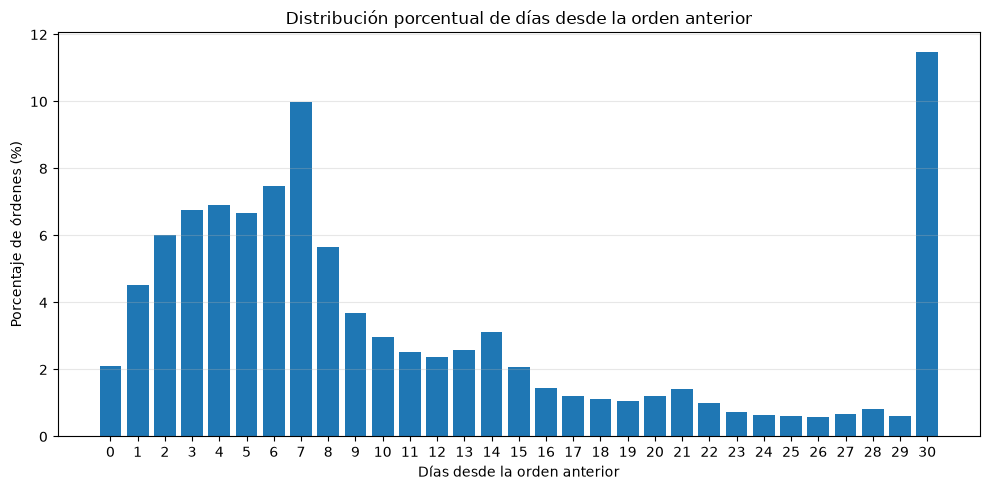

In [20]:
# ==========================================
# 6.4.7 GRÁFICA DE INTERVALOS ENTRE ÓRDENES
# ==========================================

import matplotlib.pyplot as plt


# Creamos una figura de 10 pulgadas de ancho
# por 5 pulgadas de alto.

plt.figure(figsize=(10, 5))


# Creamos una barra para cada intervalo.
#
# El eje X representa los días transcurridos.
# El eje Y representa el porcentaje de
# intervalos que corresponde a cada valor.

plt.bar(
    porcentaje_dias.index,
    porcentaje_dias.values
)


# Agregamos el título.

plt.title(
    "Distribución porcentual de días desde la orden anterior"
)


# Etiqueta del eje X.

plt.xlabel(
    "Días desde la orden anterior"
)


# Etiqueta del eje Y.

plt.ylabel(
    "Porcentaje de órdenes (%)"
)


# Mostramos todos los valores de 0 a 30
# en el eje X.

plt.xticks(range(31))


# Agregamos una cuadrícula horizontal
# para facilitar la comparación.

plt.grid(
    axis="y",
    alpha=0.3
)


# Ajustamos automáticamente los espacios
# de la gráfica.

plt.tight_layout()


# Mostramos la gráfica.

plt.show()

In [21]:
# ==========================================
# 6.3.8 ÓRDENES DENTRO DE LOS PRIMEROS 7 DÍAS
# ==========================================

# Seleccionamos los intervalos que van
# desde 0 hasta 7 días.

porcentaje_primera_semana = porcentaje_dias.loc[0:7].sum()


# Mostramos el resultado.

print(
    "Porcentaje de intervalos de 0 a 7 días:",
    round(porcentaje_primera_semana, 2),
    "%"
)

Porcentaje de intervalos de 0 a 7 días: 50.4 %


### Hallazgos: intervalo entre órdenes

El análisis de `days_since_prior_order` muestra que existen **3,214,874
intervalos válidos** entre órdenes. Los **206,209 valores nulos** detectados
anteriormente corresponden a la primera orden registrada de los usuarios, por
lo que no representan un intervalo que pueda calcularse.

La media del intervalo es de **11.11 días**, mientras que la mediana es de
**7 días**. El 50% central de los intervalos se encuentra entre **4 y 15
días**.

Al analizar la distribución de frecuencias, se observa que el **50.4% de los
intervalos corresponde a periodos de entre 0 y 7 días**.

Los valores individuales con mayor frecuencia son **30 días**, que representa
el **11.49%** de los intervalos, y **7 días**, que representa el **9.97%**.

La distribución muestra una concentración importante de intervalos cortos,
especialmente entre 2 y 7 días. Después de aproximadamente 15 días, las
frecuencias tienden a disminuir, aunque se observa nuevamente una frecuencia
elevada en el intervalo de 30 días.

Estos resultados muestran que existe una variación considerable en el tiempo
transcurrido entre órdenes y que los intervalos de recompra no se concentran
en un único periodo.

## 6.5 Comportamiento de recompra de productos

La variable `reordered` indica si un producto incluido en una orden ya había
sido comprado anteriormente por el mismo usuario.

Sus valores son:

- `0`: el producto no había sido comprado anteriormente por el usuario.
- `1`: el producto había sido comprado anteriormente por el usuario.

Esta variable permite analizar la proporción de productos que corresponden a
recompras y aquellos que representan una compra nueva para el usuario.

El análisis se realizará sobre la tabla `order_products__prior`, que contiene
los productos asociados con las órdenes históricas de los usuarios.

In [22]:
# ==========================================
# 6.4.1 FRECUENCIA DE RECOMPRA
# ==========================================

# Contamos cuántos registros existen para
# cada valor de la variable reordered.
#
# 0 → producto que no había sido comprado
#     anteriormente por el usuario.
#
# 1 → producto que ya había sido comprado
#     anteriormente por el usuario.

frecuencia_reordered = (
    order_products_prior["reordered"]
    .value_counts()
    .sort_index()
)


# Mostramos las frecuencias.

display(frecuencia_reordered)

reordered
0    13307953
1    19126536
Name: count, dtype: int64

### Porcentaje de productos recomprados

Además de conocer la cantidad de productos nuevos y recomprados, se
calculará el porcentaje que representa cada categoría respecto al total de
productos registrados en las órdenes históricas.

Esto permitirá comparar ambas categorías independientemente del número total
de registros.

In [23]:
# ==========================================
# 6.4.2 PORCENTAJE DE RECOMPRA
# ==========================================

# Calculamos el total de productos registrados
# en order_products__prior.

total_productos_prior = frecuencia_reordered.sum()


# Calculamos el porcentaje correspondiente
# a cada valor de reordered.

porcentaje_reordered = (
    frecuencia_reordered
    / total_productos_prior
) * 100


# Redondeamos los porcentajes a dos decimales
# para facilitar su interpretación.

porcentaje_reordered = porcentaje_reordered.round(2)


# Mostramos los resultados.

display(porcentaje_reordered)

reordered
0    41.03
1    58.97
Name: count, dtype: float64

### Visualización del comportamiento de recompra

Se utilizará una gráfica de barras para comparar visualmente la proporción
de productos nuevos y productos que ya habían sido comprados anteriormente.

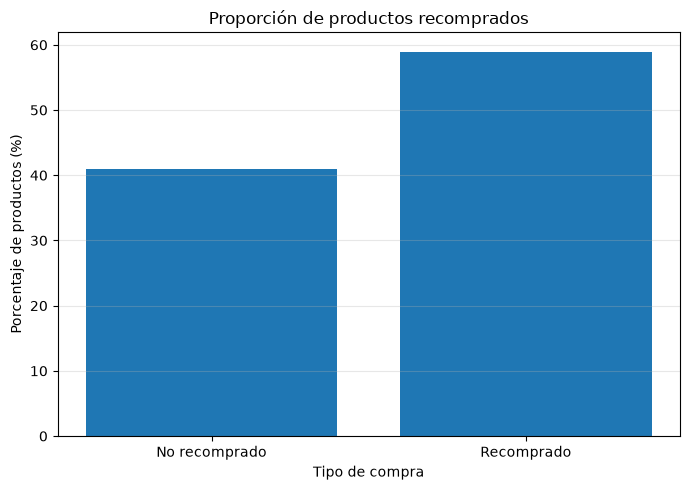

In [24]:
# ==========================================
# 6.4.3 GRÁFICA DE RECOMPRA
# ==========================================

import matplotlib.pyplot as plt


# Creamos una figura.

plt.figure(figsize=(7, 5))


# Creamos las barras utilizando los porcentajes
# calculados anteriormente.

plt.bar(
    ["No recomprado", "Recomprado"],
    porcentaje_reordered.values
)


# Agregamos el título.

plt.title(
    "Proporción de productos recomprados"
)


# Etiqueta del eje X.

plt.xlabel(
    "Tipo de compra"
)


# Etiqueta del eje Y.

plt.ylabel(
    "Porcentaje de productos (%)"
)


# Agregamos una cuadrícula horizontal
# para facilitar la comparación.

plt.grid(
    axis="y",
    alpha=0.3
)


# Ajustamos los espacios de la gráfica.

plt.tight_layout()


# Mostramos la gráfica.

plt.show()

### Hallazgos: comportamiento de recompra

El análisis de la variable `reordered` muestra que, de los **32,434,489
registros de productos** contenidos en `order_products__prior`, el **58.97%**
corresponde a productos que ya habían sido comprados anteriormente por el
usuario (`reordered = 1`).

Por otra parte, el **41.03%** de los registros corresponde a productos que no
habían sido comprados anteriormente por el usuario (`reordered = 0`).

Por lo tanto, dentro de los registros históricos de productos analizados,
los productos previamente comprados representan una proporción mayor que los
productos que aparecen por primera vez para el usuario.

Este resultado proporciona evidencia de que la recompra representa una parte
importante de las transacciones registradas en el dataset. Sin embargo, el
resultado se refiere a registros de productos y no directamente a usuarios,
por lo que no debe interpretarse como el porcentaje de clientes que realizan
recompras.

## 6.6 Posición de los productos dentro de la orden

La variable `add_to_cart_order` representa la posición en la que cada
producto fue agregado al carrito dentro de una orden.

Por ejemplo, un valor de `1` indica que el producto fue el primero agregado,
mientras que un valor mayor indica una posición posterior.

Esta variable permitirá analizar la distribución de las posiciones de los
productos dentro de las órdenes y obtener información sobre la estructura de
las compras.

In [25]:
# ==========================================
# 6.5.1 ESTADÍSTICA DESCRIPTIVA
#     DE ADD_TO_CART_ORDER
# ==========================================

# Calculamos las principales estadísticas
# descriptivas de la posición de los productos.

display(
    order_products_prior["add_to_cart_order"].describe()
)

count    3.243449e+07
mean     8.351076e+00
std      7.126671e+00
min      1.000000e+00
25%      3.000000e+00
50%      6.000000e+00
75%      1.100000e+01
max      1.450000e+02
Name: add_to_cart_order, dtype: float64

### Cantidad de productos por orden

Debido a que `add_to_cart_order` representa la posición de cada producto
dentro de una orden, el valor máximo de esta variable para cada `order_id`
permite aproximar la cantidad de productos registrados en esa orden.

Se calculará esta cantidad para posteriormente analizar la distribución del
tamaño de las órdenes.

In [26]:
# ==========================================
# 6.5.2 CANTIDAD DE PRODUCTOS POR ORDEN
# ==========================================

# Agrupamos los registros por order_id.
#
# Para cada orden obtenemos el valor máximo
# de add_to_cart_order.
#
# Como la posición empieza en 1, el valor
# máximo representa la cantidad de productos
# registrados en esa orden.

productos_por_orden = (
    order_products_prior
    .groupby("order_id")["add_to_cart_order"]
    .max()
)


# Mostramos las estadísticas descriptivas
# de la cantidad de productos por orden.

display(
    productos_por_orden.describe()
)

count    3.214874e+06
mean     1.008888e+01
std      7.525398e+00
min      1.000000e+00
25%      5.000000e+00
50%      8.000000e+00
75%      1.400000e+01
max      1.450000e+02
Name: add_to_cart_order, dtype: float64

### Hallazgos: cantidad de productos por orden

A partir de `add_to_cart_order` se calculó la cantidad de productos
registrados en cada orden utilizando el valor máximo de la posición de
agregado al carrito.

La cantidad promedio de productos por orden es de aproximadamente **10.09
productos**, mientras que la mediana es de **8 productos**.

El 50% central de las órdenes contiene entre **5 y 14 productos**. Se
observa además una diferencia entre la media y la mediana, así como órdenes
con cantidades considerablemente mayores de productos, alcanzando un máximo
de **145 productos**.

Estos resultados permiten caracterizar el tamaño de las órdenes y serán
considerados durante las etapas posteriores de procesamiento de los datos.

## 6.7 Número de orden del usuario

La variable `order_number` representa el número secuencial de la orden
realizada por cada usuario.

Por ejemplo, para un mismo usuario, los valores 1, 2 y 3 representan
respectivamente su primera, segunda y tercera orden registrada.

Esta variable permite analizar la cantidad de órdenes registradas por usuario
y conocer cómo se distribuye la recurrencia de compra dentro del conjunto de
datos.

In [27]:
# ==========================================
# 6.7.1 ESTADÍSTICA DESCRIPTIVA
#     DE ORDER_NUMBER
# ==========================================

# Calculamos las estadísticas descriptivas
# del número de orden.

display(
    orders["order_number"].describe()
)

count    3.421083e+06
mean     1.715486e+01
std      1.773316e+01
min      1.000000e+00
25%      5.000000e+00
50%      1.100000e+01
75%      2.300000e+01
max      1.000000e+02
Name: order_number, dtype: float64

### Cantidad de órdenes por usuario

Para conocer la cantidad de órdenes realizadas por cada usuario, se agruparán
los registros de `orders` mediante `user_id`.

El valor máximo de `order_number` de cada usuario representa su número de
orden más alto registrado y, por lo tanto, permite obtener la cantidad de
órdenes registradas para dicho usuario.

In [28]:
# ==========================================
# 6.7.2 ÓRDENES POR USUARIO
# ==========================================

# Agrupamos las órdenes utilizando user_id.
#
# Para cada usuario obtenemos el número máximo
# de order_number.
#
# Como order_number comienza en 1 y aumenta
# secuencialmente, este valor representa
# la cantidad de órdenes registradas para
# ese usuario.

ordenes_por_usuario = (
    orders
    .groupby("user_id")["order_number"]
    .max()
)


# Mostramos las estadísticas descriptivas
# de la cantidad de órdenes por usuario.

display(
    ordenes_por_usuario.describe()
)

count    206209.000000
mean         16.590367
std          16.654774
min           4.000000
25%           6.000000
50%          10.000000
75%          20.000000
max         100.000000
Name: order_number, dtype: float64

### Hallazgos: recurrencia de los usuarios

El análisis de `order_number` agrupado por `user_id` muestra que el dataset
contiene **206,209 usuarios** con órdenes registradas.

La cantidad promedio de órdenes registradas por usuario es de **16.59**,
mientras que la mediana es de **10 órdenes**. El 50% central de los usuarios
presenta entre **6 y 20 órdenes registradas**.

El número mínimo de órdenes registradas para un usuario es de **1**, mientras
que el máximo es de **100 órdenes**.

La diferencia entre la media y la mediana indica que existen usuarios con un
número elevado de órdenes registradas, lo que genera una distribución
asimétrica hacia valores altos.

Estos resultados permiten caracterizar la recurrencia de los usuarios y serán
considerados posteriormente durante la construcción del dataset para
aprendizaje.

## 6.8 Principales hallazgos del análisis estadístico

A partir del análisis realizado se encontraron los siguientes resultados
importantes sobre el comportamiento de las compras:

1. **Día y hora de las compras:** las órdenes no se distribuyen de manera
   uniforme durante la semana ni durante el día. Hay días y horarios en los
   que se realizan muchas más compras que en otros. Las órdenes se concentran
   principalmente durante el día y disminuyen durante la madrugada.

2. **Tiempo entre compras:** la mitad de los intervalos entre órdenes es de
   **7 días o menos**. Además, el **50.4% de los intervalos** se encuentra
   entre 0 y 7 días. También se observa una cantidad importante de órdenes
   con un intervalo de **30 días**.

3. **Productos que vuelven a comprarse:** de todos los productos registrados
   en las órdenes históricas, el **58.97% ya había sido comprado anteriormente
   por el usuario**, mientras que el **41.03% correspondía a productos que no
   habían sido comprados anteriormente**. Esto muestra que las compras de
   productos que los usuarios ya conocen representan una parte importante de
   las órdenes.

4. **Tamaño de las órdenes:** una orden contiene normalmente varios productos.
   La cantidad mediana es de **8 productos por orden**. La mitad de las órdenes
   contiene entre **5 y 14 productos**.

5. **Cantidad de órdenes por usuario:** los usuarios tienen una cantidad
   diferente de órdenes registradas. La mediana es de **10 órdenes por
   usuario**, mientras que la mitad de los usuarios tiene entre **6 y 20
   órdenes registradas**.

Estos resultados permiten conocer mejor cómo se comportan las compras dentro
del dataset y servirán como base para decidir qué información utilizar y cómo
transformarla durante la construcción del dataset para aprendizaje.

## 7. Procesamiento de los datos

### 7.1 Definición del dataset base
### 7.2 Integración de las tablas
### 7.3 Selección de variables
### 7.4 Tratamiento de valores faltantes
### 7.5 Verificación de duplicados y consistencia
### 7.6 Dataset procesado

## 7. Procesamiento de los datos

### 7.1 Definición del dataset base

El procesamiento de los datos tiene como finalidad integrar y preparar la información necesaria para las etapas posteriores de minería de datos y aprendizaje automático. Debido a que el conjunto de datos de Instacart se encuentra distribuido en diferentes tablas, primero es necesario establecer la unidad de análisis que tendrá el dataset procesado.

Para este proyecto se utilizará como unidad de análisis el **producto perteneciente a un pedido realizado por un usuario**. Por lo tanto, cada fila del dataset base representará la relación entre un usuario, un pedido y un producto adquirido dentro de dicho pedido.

Esta estructura permite conservar el nivel de detalle de las transacciones originales y posteriormente generar diferentes estructuras de análisis a partir de ellas. En particular, el dataset podrá utilizarse como base para tres líneas de análisis:

* **Reglas de asociación:** analizar los productos que aparecen conjuntamente dentro de un mismo pedido.
* **Clustering:** agrupar y caracterizar usuarios de acuerdo con las características de su comportamiento de compra.
* **Clasificación:** analizar la recompra de productos utilizando la variable `reordered` como variable objetivo.

```

                    DATASET BASE
                         │
          ┌──────────────┼──────────────┐
          │              │              │
          ▼              ▼              ▼
      Asociación      Clustering    Clasificación
      productos       usuarios       recompra
```  

Por esta razón, no se construirá inicialmente un dataset independiente para cada técnica. En su lugar, se generará un **dataset base integrado**, conservando las variables necesarias para posteriormente realizar las transformaciones específicas requeridas por cada técnica.

La estructura general que se busca obtener es:

| Elemento                 | Representación                        |
| ------------------------ | ------------------------------------- |
| Unidad de análisis       | Producto dentro de un pedido          |
| Usuario                  | `user_id`                             |
| Pedido                   | `order_id`                            |
| Producto                 | `product_id`                          |
| Información del producto | `product_name`, `aisle`, `department` |
| Información del pedido   | `order_number`, `add_to_cart_order`   |
| Variable de recompra     | `reordered`                           |

La elección de esta estructura permite conservar información suficiente para analizar las transacciones desde diferentes perspectivas sin perder el detalle de los productos adquiridos.


### 7.2.1 Integración de `order_products_prior` con `orders`

La primera etapa de integración consiste en unir la información de los productos
adquiridos con la información correspondiente a los pedidos en los que fueron
registrados.

La tabla `order_products_prior` contiene información sobre los productos
incluidos en los pedidos realizados durante el periodo histórico (`prior`),
mientras que la tabla `orders` contiene información general de cada pedido,
incluyendo el usuario que lo realizó, el número de pedido y otras variables
relacionadas con el comportamiento temporal de la compra.

La relación entre ambas tablas se establece mediante la variable `order_id`,
que identifica de manera única cada pedido.

Se utilizará una unión de tipo `inner`, ya que se busca conservar únicamente
los registros que tengan correspondencia entre ambas tablas. En el análisis
previo de las relaciones entre las tablas se verificó que los identificadores
de pedido presentes en `order_products_prior` cuentan con correspondencia en
la tabla `orders`.

El objetivo de esta integración es agregar a cada registro de producto la
información del usuario y del pedido al que pertenece, manteniendo como unidad
de análisis el producto adquirido dentro de un pedido.

In [29]:
# Integramos los productos comprados con la información de sus respectivos pedidos.
# La unión se realiza utilizando order_id como clave de relación.

orders_products = order_products_prior.merge(
    orders,
    on="order_id",
    how="inner"
)

# Mostramos los primeros registros para comprobar el resultado de la integración.
orders_products.head()

,order_id,product_id,add_to_cart_order,reordered,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order
0,2,33120,1,1,202279,prior,3,5,9,8.0
1,2,28985,2,1,202279,prior,3,5,9,8.0
2,2,9327,3,0,202279,prior,3,5,9,8.0
3,2,45918,4,1,202279,prior,3,5,9,8.0
4,2,30035,5,0,202279,prior,3,5,9,8.0


### Verificación de la integración

Después de realizar la unión se verifica el tamaño del dataset resultante y
las columnas obtenidas.

Debido a que la unión se realiza utilizando `order_id` y que cada registro de
`order_products_prior` representa un producto perteneciente a un pedido, la
integración debe conservar el número de registros de productos siempre que
exista una correspondencia válida con la tabla `orders`.

La comparación del número de filas antes y después de la unión permite detectar
posibles pérdidas o multiplicaciones inesperadas de registros.

In [30]:
# Comparamos el número de filas antes y después de realizar la integración.
print("Filas antes del merge:", len(order_products_prior))
print("Filas después del merge:", len(orders_products))

# Mostramos la cantidad de filas y columnas del dataset resultante.
print("\nDimensiones del dataset integrado:")
print(orders_products.shape)

# Mostramos las columnas disponibles después de la integración.
print("\nColumnas del dataset integrado:")
print(orders_products.columns.tolist())

Filas antes del merge: 32434489
Filas después del merge: 32434489

Dimensiones del dataset integrado:
(32434489, 10)

Columnas del dataset integrado:
['order_id', 'product_id', 'add_to_cart_order', 'reordered', 'user_id', 'eval_set', 'order_number', 'order_dow', 'order_hour_of_day', 'days_since_prior_order']


### Verificación de registros duplicados

Como parte del control de calidad del dataset integrado, se verifica la
existencia de registros completamente duplicados.

Esta comprobación permite detectar si la operación de integración generó
filas idénticas de manera inesperada.

Esta prueba se realiza sobre todas las columnas disponibles en el dataset
resultante.

In [31]:
# Contamos los registros completamente duplicados en el dataset integrado.
duplicados = orders_products.duplicated().sum()

print("Registros completamente duplicados:", duplicados)

Registros completamente duplicados: 0


### Conclusión de la integración

La integración entre `order_products_prior` y `orders` se realizó mediante la
variable `order_id` utilizando una unión de tipo `inner`.

El resultado conserva los **32,434,489 registros** originales de
`order_products_prior`, por lo que no se presentaron pérdidas de registros
durante esta operación. El dataset resultante contiene **10 variables**, en
las cuales se combina la información de los productos adquiridos con los
datos correspondientes al usuario y al pedido.

Asimismo, la verificación realizada no encontró registros completamente
duplicados en el dataset resultante.

Con esta integración se obtiene una primera estructura que permite relacionar
cada producto adquirido con el usuario y el pedido al que pertenece, por lo
que se mantiene la unidad de análisis definida para el proyecto.

### 7.2.2 Integración con la información de los productos

La segunda etapa de integración consiste en incorporar al dataset la
información descriptiva de los productos adquiridos.

La tabla `products` contiene información asociada a cada producto mediante
la variable `product_id`, además de identificar el pasillo (`aisle_id`) y
el departamento (`department_id`) al que pertenece.

La relación entre `orders_products` y `products` se establece mediante
`product_id`.

Se utilizará una unión de tipo `inner`, ya que se busca conservar los
registros de productos que tengan correspondencia en la tabla `products`.
En el análisis previo de las relaciones entre las tablas se verificó que
los identificadores de producto presentes en `order_products_prior` cuentan
con correspondencia en la tabla `products`.

La relación esperada entre ambas tablas es de muchos a uno: un mismo
producto puede aparecer en múltiples registros de pedidos, mientras que
cada `product_id` aparece una sola vez en la tabla `products`.

Esta integración permitirá incorporar al dataset el nombre del producto y
los identificadores de su pasillo y departamento.

In [36]:
# Reconstruimos orders_products a partir de las tablas originales.
# Esto evita conservar columnas generadas por ejecuciones anteriores
# del notebook.

orders_products = order_products_prior.merge(
    orders,
    on="order_id",
    how="inner",
    validate="many_to_one"
)

# Guardamos el número de filas antes de integrar products.
filas_antes_products = len(orders_products)

# Comprobamos que la primera integración tenga la estructura esperada.
print("Filas después de integrar orders:", len(orders_products))
print("Dimensiones:", orders_products.shape)
print("\nColumnas:")
print(orders_products.columns.tolist())

Filas después de integrar orders: 32434489
Dimensiones: (32434489, 10)

Columnas:
['order_id', 'product_id', 'add_to_cart_order', 'reordered', 'user_id', 'eval_set', 'order_number', 'order_dow', 'order_hour_of_day', 'days_since_prior_order']


In [37]:
# Integramos la información descriptiva de los productos.
# La relación se establece mediante product_id.
#
# validate="many_to_one" comprueba que múltiples registros de
# pedidos puedan relacionarse con un único registro de products.

orders_products = orders_products.merge(
    products,
    on="product_id",
    how="inner",
    validate="many_to_one"
)

# Mostramos los primeros registros para comprobar el resultado.
orders_products.head()

,order_id,product_id,add_to_cart_order,reordered,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order,product_name,aisle_id,department_id
0,2,33120,1,1,202279,prior,3,5,9,8.0,Organic Egg Whites,86,16
1,2,28985,2,1,202279,prior,3,5,9,8.0,Michigan Organic Kale,83,4
2,2,9327,3,0,202279,prior,3,5,9,8.0,Garlic Powder,104,13
3,2,45918,4,1,202279,prior,3,5,9,8.0,Coconut Butter,19,13
4,2,30035,5,0,202279,prior,3,5,9,8.0,Natural Sweetener,17,13


### Verificación de la integración con `products`

Después de realizar la integración se compara el número de registros antes
y después de la unión.

Debido a que cada `product_id` de `orders_products` debe tener una
correspondencia en la tabla `products`, se espera que el número de filas se
mantenga.

También se revisan las dimensiones y las columnas disponibles para comprobar
que la información descriptiva de los productos se haya incorporado
correctamente.

In [38]:
# Comparamos el número de filas antes y después del merge.
print("Filas antes del merge con products:", filas_antes_products)
print("Filas después del merge con products:", len(orders_products))

# Mostramos las dimensiones actuales del dataset.
print("\nDimensiones del dataset:")
print(orders_products.shape)

# Mostramos las columnas disponibles después de integrar products.
print("\nColumnas del dataset:")
print(orders_products.columns.tolist())

Filas antes del merge con products: 32434489
Filas después del merge con products: 32434489

Dimensiones del dataset:
(32434489, 13)

Columnas del dataset:
['order_id', 'product_id', 'add_to_cart_order', 'reordered', 'user_id', 'eval_set', 'order_number', 'order_dow', 'order_hour_of_day', 'days_since_prior_order', 'product_name', 'aisle_id', 'department_id']


### Verificación de registros duplicados

Como parte del control de calidad del dataset integrado, se verifica la
existencia de registros completamente duplicados después de incorporar la
información de `products`.

Esta comprobación permite identificar si la integración generó filas
idénticas de manera inesperada.

In [39]:
# Contamos los registros completamente duplicados después
# de integrar la información de products.

duplicados = orders_products.duplicated().sum()

print("Registros completamente duplicados:", duplicados)

Registros completamente duplicados: 0


### Conclusión de la integración con `products`

La integración de la tabla `products` se realizó mediante la variable
`product_id`, manteniendo la unidad de análisis definida previamente:
cada fila representa un producto perteneciente a un pedido realizado por
un usuario.

La cantidad de registros se mantiene después de la integración, por lo
que no se presentaron pérdidas de registros durante la unión. Además, se
incorporó información descriptiva del producto mediante las variables
`product_name`, `aisle_id` y `department_id`.

Con esta etapa se cuenta con información suficiente para identificar cada
producto y relacionarlo posteriormente con su pasillo y departamento.

### 7.2.3 Integración con `aisles` y `departments`

#### 7.2.3.1 Integración con `aisles`

La tabla `aisles` contiene la información descriptiva asociada a los
identificadores de pasillo presentes en la tabla `products`.

En el dataset actual, cada producto cuenta con un identificador `aisle_id`,
pero este valor numérico por sí solo no permite interpretar directamente
el tipo de pasillo al que pertenece el producto.

Por esta razón, se integrará la tabla `aisles` utilizando `aisle_id` como
clave de relación. La unión será de tipo `inner` y se espera una relación
de muchos a uno: múltiples registros de pedidos pueden pertenecer al mismo
pasillo, mientras que cada `aisle_id` aparece una sola vez en la tabla
`aisles`.

Esta integración permitirá incorporar al dataset el nombre descriptivo del
pasillo correspondiente a cada producto.

In [40]:
# Guardamos el número de filas antes de integrar la información de los pasillos.
filas_antes_aisles = len(orders_products)

# Integramos la información descriptiva de los pasillos.
# La relación se establece mediante aisle_id.
#
# validate="many_to_one" comprueba que múltiples registros de pedidos
# puedan relacionarse con un único registro de la tabla aisles.

orders_products = orders_products.merge(
    aisles,
    on="aisle_id",
    how="inner",
    validate="many_to_one"
)

# Mostramos los primeros registros para comprobar el resultado.
orders_products.head()

,order_id,product_id,add_to_cart_order,reordered,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order,product_name,aisle_id,department_id,aisle
0,2,33120,1,1,202279,prior,3,5,9,8.0,Organic Egg Whites,86,16,eggs
1,2,28985,2,1,202279,prior,3,5,9,8.0,Michigan Organic Kale,83,4,fresh vegetables
2,2,9327,3,0,202279,prior,3,5,9,8.0,Garlic Powder,104,13,spices seasonings
3,2,45918,4,1,202279,prior,3,5,9,8.0,Coconut Butter,19,13,oils vinegars
4,2,30035,5,0,202279,prior,3,5,9,8.0,Natural Sweetener,17,13,baking ingredients


### Verificación de la integración con `aisles`

Después de integrar la tabla `aisles`, se compara el número de registros
antes y después de la unión.

Como cada `aisle_id` presente en el dataset debe corresponder con un registro
de la tabla `aisles`, se espera que el número de filas se mantenga.

También se revisan las dimensiones y las columnas disponibles para confirmar
que la información descriptiva del pasillo fue incorporada correctamente.

In [41]:
# Comparamos el número de filas antes y después del merge.
print("Filas antes del merge con aisles:", filas_antes_aisles)
print("Filas después del merge con aisles:", len(orders_products))

# Mostramos las dimensiones actuales del dataset.
print("\nDimensiones del dataset:")
print(orders_products.shape)

# Mostramos las columnas disponibles después de integrar aisles.
print("\nColumnas del dataset:")
print(orders_products.columns.tolist())

Filas antes del merge con aisles: 32434489
Filas después del merge con aisles: 32434489

Dimensiones del dataset:
(32434489, 14)

Columnas del dataset:
['order_id', 'product_id', 'add_to_cart_order', 'reordered', 'user_id', 'eval_set', 'order_number', 'order_dow', 'order_hour_of_day', 'days_since_prior_order', 'product_name', 'aisle_id', 'department_id', 'aisle']


### Verificación de registros duplicados después de integrar `aisles`

Se verifica nuevamente la existencia de registros completamente duplicados
después de incorporar la información descriptiva de los pasillos.

Esta comprobación forma parte del control de calidad realizado después de
cada integración.

In [42]:
# Contamos los registros completamente duplicados después
# de integrar la información de aisles.

duplicados_aisles = orders_products.duplicated().sum()

print(
    "Registros completamente duplicados después de integrar aisles:",
    duplicados_aisles
)

Registros completamente duplicados después de integrar aisles: 0


#### 7.2.3.2 Integración con `departments`

La tabla `departments` contiene la información descriptiva correspondiente
a los identificadores de departamento presentes en la tabla `products`.

El dataset actual contiene la variable `department_id`, que permite
identificar numéricamente el departamento al que pertenece cada producto.

Para facilitar la interpretación de los datos, se integrará la tabla
`departments` utilizando `department_id` como clave de relación.

La relación esperada es de muchos a uno: múltiples registros de pedidos
pueden pertenecer al mismo departamento, mientras que cada
`department_id` aparece una sola vez en la tabla `departments`.

Esta integración permitirá incorporar al dataset el nombre descriptivo del
departamento correspondiente a cada producto.

In [43]:
# Guardamos el número de filas antes de integrar los departamentos.
filas_antes_departments = len(orders_products)

# Integramos la información descriptiva de los departamentos.
# La relación se establece mediante department_id.
#
# validate="many_to_one" comprueba que múltiples registros de pedidos
# puedan relacionarse con un único registro de departments.

orders_products = orders_products.merge(
    departments,
    on="department_id",
    how="inner",
    validate="many_to_one"
)

# Mostramos los primeros registros para comprobar el resultado.
orders_products.head()

,order_id,product_id,add_to_cart_order,reordered,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order,product_name,aisle_id,department_id,aisle,department
0,2,33120,1,1,202279,prior,3,5,9,8.0,Organic Egg Whites,86,16,eggs,dairy eggs
1,2,28985,2,1,202279,prior,3,5,9,8.0,Michigan Organic Kale,83,4,fresh vegetables,produce
2,2,9327,3,0,202279,prior,3,5,9,8.0,Garlic Powder,104,13,spices seasonings,pantry
3,2,45918,4,1,202279,prior,3,5,9,8.0,Coconut Butter,19,13,oils vinegars,pantry
4,2,30035,5,0,202279,prior,3,5,9,8.0,Natural Sweetener,17,13,baking ingredients,pantry


### Verificación de la integración con `departments`

Después de integrar la tabla `departments`, se compara el número de
registros antes y después de la unión.

Se espera que el número de filas se mantenga, ya que cada
`department_id` presente en el dataset debe contar con una correspondencia
en la tabla `departments`.

También se revisan las dimensiones y las columnas disponibles para
comprobar que la información descriptiva del departamento se haya
incorporado correctamente.

In [44]:
# Comparamos el número de filas antes y después del merge.
print("Filas antes del merge con departments:", filas_antes_departments)
print("Filas después del merge con departments:", len(orders_products))

# Mostramos las dimensiones actuales del dataset.
print("\nDimensiones del dataset:")
print(orders_products.shape)

# Mostramos las columnas disponibles después de integrar departments.
print("\nColumnas del dataset:")
print(orders_products.columns.tolist())

Filas antes del merge con departments: 32434489
Filas después del merge con departments: 32434489

Dimensiones del dataset:
(32434489, 15)

Columnas del dataset:
['order_id', 'product_id', 'add_to_cart_order', 'reordered', 'user_id', 'eval_set', 'order_number', 'order_dow', 'order_hour_of_day', 'days_since_prior_order', 'product_name', 'aisle_id', 'department_id', 'aisle', 'department']


### Verificación final de registros duplicados

Después de completar las integraciones con `aisles` y `departments`, se
realiza una última comprobación de registros completamente duplicados.

Esta verificación permite confirmar que las dos integraciones no generaron
filas idénticas de manera inesperada.

In [45]:
# Contamos los registros completamente duplicados después
# de completar las integraciones de aisles y departments.

duplicados_finales = orders_products.duplicated().sum()

print(
    "Registros completamente duplicados después de integrar aisles y departments:",
    duplicados_finales
)

Registros completamente duplicados después de integrar aisles y departments: 0


### Conclusión de la integración con `aisles` y `departments`

Se integraron las tablas `aisles` y `departments` utilizando `aisle_id` y
`department_id`, respectivamente, como claves de relación.

Ambas integraciones permiten complementar la información numérica de los
identificadores con sus correspondientes nombres descriptivos, facilitando
la interpretación de los productos dentro de sus categorías.

La cantidad de registros se mantiene durante las integraciones, mientras
que el número de variables aumenta al incorporar la información descriptiva
de los pasillos y departamentos.

Los identificadores `aisle_id` y `department_id` se conservarán
temporalmente junto con sus respectivas variables descriptivas. La decisión
sobre qué variables conservar definitivamente se realizará posteriormente,
durante la etapa de selección de variables del dataset.

Nuestro proceso hasta ahora quedó:
```
                 INSTACART
                    │
        ┌───────────┴───────────┐
        │                       │
order_products_prior          orders
        │                       │
        └───────────┬───────────┘
                    │
                    ▼
             orders_products
             32,434,489 × 10
                    │
                    ▼
                products
                    │
                    ▼
             32,434,489 × 13
                    │
              ┌─────┴─────┐
              ▼           ▼
           aisles     departments
              │           │
              └─────┬─────┘
                    ▼
          DATASET INTEGRADO
          32,434,489 × 15
```          

## 7.3 Selección de variables

Una vez completada la integración de las tablas, se cuenta con un dataset
de 32,434,489 registros y 15 variables.

La selección de variables no se realizará únicamente con base en el tipo de
dato, sino considerando la función que cada variable puede desempeñar en
las tres líneas de aprendizaje planteadas:

- Análisis de asociación entre productos.
- Segmentación de usuarios mediante clustering.
- Clasificación orientada al comportamiento de recompra.

Antes de eliminar variables, se clasifican de acuerdo con su función dentro
del dataset. De esta manera se evita descartar información que pueda ser
necesaria para construir posteriormente datasets específicos para cada
técnica.

### 7.3.1.1 Identificadores

Las variables `order_id`, `product_id`, `user_id`, `aisle_id` y
`department_id` funcionan principalmente como identificadores o claves de
relación.

Estas variables son necesarias para relacionar registros y construir
agrupaciones, pero no deben interpretarse directamente como características
numéricas del comportamiento.

Por ejemplo, el valor de `user_id` solamente identifica a un usuario y su
magnitud numérica no representa una característica de dicho usuario.

Por esta razón, estos identificadores se conservarán durante las etapas de
transformación y construcción de los datasets derivados, pero no se
utilizarán directamente como variables predictoras numéricas.

### 7.3.1.2 Variables de comportamiento de compra

Las variables `add_to_cart_order`, `reordered`, `order_number`,
`order_dow`, `order_hour_of_day` y `days_since_prior_order` contienen
información relacionada con el comportamiento de compra.

Estas variables pueden utilizarse para construir características de los
usuarios y de sus pedidos.

En particular, `reordered` representa si un producto fue comprado
nuevamente dentro del pedido analizado, por lo que será una variable
especialmente relevante para la línea de clasificación.

Por otra parte, variables como `order_number`, `order_dow`,
`order_hour_of_day` y `days_since_prior_order` pueden utilizarse para
caracterizar la frecuencia y temporalidad de las compras.

### 7.3.1.3 Variables descriptivas de los productos

Las variables `product_name`, `aisle` y `department` proporcionan
información descriptiva sobre los productos.

`product_name` permite identificar el producto específico, mientras que
`aisle` y `department` permiten representar categorías de productos con
diferentes niveles de agrupación.

Estas variables serán especialmente relevantes para el análisis de
asociación y para la construcción de características relacionadas con las
preferencias de compra de los usuarios.

Su utilización en los algoritmos de aprendizaje dependerá de la
transformación que se realice posteriormente, ya que se trata de variables
categóricas.

### 7.3.1.4 Variable `eval_set`

La variable `eval_set` identifica el conjunto al que pertenece cada pedido
dentro del dataset original de Instacart.

El dataset integrado utilizado en esta etapa se construyó a partir de
`order_products_prior` y de la información correspondiente de `orders`.
Por lo tanto, los registros integrados corresponden al conjunto de pedidos
históricos utilizado para el análisis.

Debido a que esta variable no representa directamente una característica
del comportamiento de compra y no aporta información necesaria para las
tres líneas de aprendizaje planteadas, no será considerada como variable
predictora.

Se conservará únicamente mientras sea necesaria para mantener la trazabilidad
con respecto al dataset original.

### Resumen de la clasificación de variables

A partir del análisis realizado previamente y de la función que desempeña
cada variable, se establece la siguiente clasificación:

| Variable | Función | Uso principal |
|---|---|---|
| `order_id` | Identificador de pedido | Asociación y agrupaciones |
| `product_id` | Identificador de producto | Asociación y agrupaciones |
| `user_id` | Identificador de usuario | Clustering y agrupaciones |
| `aisle_id` | Identificador de categoría | Relación y agrupaciones |
| `department_id` | Identificador de categoría | Relación y agrupaciones |
| `add_to_cart_order` | Comportamiento | Clasificación y características |
| `reordered` | Comportamiento / objetivo | Clasificación |
| `order_number` | Comportamiento | Clustering y clasificación |
| `order_dow` | Temporal | Clustering y clasificación |
| `order_hour_of_day` | Temporal | Clustering y clasificación |
| `days_since_prior_order` | Temporal / frecuencia | Clustering y clasificación |
| `product_name` | Descriptiva | Asociación y características |
| `aisle` | Descriptiva / categórica | Asociación y características |
| `department` | Descriptiva / categórica | Asociación y características |
| `eval_set` | Identificador de conjunto | Trazabilidad |

Esta clasificación permitirá conservar inicialmente las variables necesarias
y realizar posteriormente transformaciones específicas para cada una de las
tres líneas de aprendizaje.

La estrategia será:

```
                 DATASET INTEGRADO
                 32,434,489 × 15
                         │
                         ▼
                Clasificación de
                   variables
                         │
             ┌───────────┼───────────┐
             ▼           ▼           ▼
        Asociación   Clustering  Clasificación
             │           │           │
             ▼           ▼           ▼
          Dataset A   Dataset B    Dataset C
```

Cada uno tendrá una unidad de análisis diferente.

### 7.3.2 Variables necesarias para el análisis de asociación

El análisis de asociación busca identificar relaciones frecuentes entre
productos que aparecen dentro de los mismos pedidos.

Para esta tarea, la unidad de análisis será el pedido. Cada pedido deberá
poder representarse como un conjunto de productos adquiridos.

Las variables fundamentales serán:

- `order_id`: identifica el pedido al que pertenece cada registro.
- `product_id`: identifica el producto incluido en el pedido.
- `product_name`: proporciona una representación interpretable del producto.

Las variables relacionadas con el usuario, horario y características
temporales no son necesarias para construir la estructura básica de
canastas de productos, por lo que no serán utilizadas directamente en esta
transformación.

A partir del dataset integrado se podrá construir posteriormente una
estructura en la que cada pedido represente una transacción y los productos
representen los elementos de dicha transacción.

### 7.3.3 Variables necesarias para el análisis de clustering

El análisis de clustering tendrá como objetivo identificar grupos de
usuarios con comportamientos de compra similares.

En este caso, la unidad de análisis cambiará: en lugar de representar un
producto dentro de un pedido, cada fila del dataset derivado representará
a un usuario.

Para construir las características de cada usuario se utilizarán
principalmente las variables:

- `user_id`: identificador del usuario.
- `order_number`: permite obtener información sobre el número de pedidos.
- `add_to_cart_order`: permite caracterizar el tamaño de los pedidos.
- `reordered`: permite calcular indicadores relacionados con la recompra.
- `order_dow`: permite caracterizar los días de compra.
- `order_hour_of_day`: permite caracterizar los horarios de compra.
- `days_since_prior_order`: permite obtener información relacionada con
  la frecuencia entre pedidos.
- `department` y `aisle`: permiten incorporar información sobre las
  categorías de productos adquiridos.

Estas variables no se utilizarán necesariamente de forma directa. Algunas
de ellas deberán transformarse mediante operaciones de agregación para
construir características numéricas por usuario.

### 7.3.4 Variables necesarias para el análisis de clasificación

El análisis de clasificación estará orientado al comportamiento de
recompra de productos.

La variable `reordered` será considerada como variable objetivo, ya que
indica si el producto registrado en el pedido corresponde a una recompra.

Las variables candidatas para construir las características predictoras
incluyen:

- `order_number`
- `add_to_cart_order`
- `order_dow`
- `order_hour_of_day`
- `days_since_prior_order`
- `department`
- `aisle`

Los identificadores como `order_id`, `product_id` y `user_id` no serán
utilizados directamente como variables numéricas predictoras.

La variable `reordered` deberá mantenerse separada de las características
predictoras cuando se construya el dataset destinado al aprendizaje, con
el propósito de diferenciar las variables de entrada de la variable
objetivo.

### 7.3.5 Conclusión de la selección de variables

A partir de la clasificación realizada, se determina que no es conveniente
eliminar inmediatamente las variables del dataset integrado, debido a que
las tres líneas de aprendizaje requieren diferentes representaciones de
los datos.

El dataset integrado se conservará como dataset base y posteriormente se
generarán estructuras específicas para cada objetivo:

1. **Asociación:** pedidos representados como conjuntos de productos.
2. **Clustering:** usuarios representados mediante características
   agregadas de su comportamiento de compra.
3. **Clasificación:** registros representados mediante características de
   comportamiento y una variable objetivo relacionada con la recompra.

Esta estrategia permite conservar la información disponible y evitar
pérdidas prematuras de variables que puedan resultar útiles durante las
transformaciones posteriores.

In [46]:
# Mostramos las variables disponibles en el dataset integrado.
# Esta lista sirve como referencia para la selección y transformación
# posterior de variables.

variables_dataset = orders_products.columns.tolist()

print("Número de variables:", len(variables_dataset))
print("\nVariables disponibles:")

for variable in variables_dataset:
    print("-", variable)

Número de variables: 15

Variables disponibles:
- order_id
- product_id
- add_to_cart_order
- reordered
- user_id
- eval_set
- order_number
- order_dow
- order_hour_of_day
- days_since_prior_order
- product_name
- aisle_id
- department_id
- aisle
- department


## 7.4 Tratamiento de valores faltantes

Durante el análisis exploratorio realizado previamente se identificó que
la variable `days_since_prior_order` contiene valores faltantes.

Estos valores no representan necesariamente información ausente por un
error en los datos. En el dataset de Instacart, la ausencia de un valor en
esta variable se relaciona con los pedidos que no cuentan con un pedido
anterior del mismo usuario.

Por lo tanto, antes de aplicar una estrategia de imputación, se debe
considerar el significado de la variable y el contexto en el que aparece
el valor faltante.

Debido a que los primeros pedidos también contienen información relevante
para el análisis de comportamiento de compra, no se eliminarán los
registros que presentan estos valores.

# Comprobamos qué número de pedido tienen los registros
# donde days_since_prior_order presenta valores faltantes.

primer_pedido_nulos = orders_products.loc[
    orders_products["days_since_prior_order"].isna(),
    "order_number"
].value_counts().sort_index()

print("Distribución de order_number en los registros con")
print("days_since_prior_order faltante:\n")
print(primer_pedido_nulos)

In [47]:
# Comprobamos qué número de pedido tienen los registros
# donde days_since_prior_order presenta valores faltantes.

primer_pedido_nulos = orders_products.loc[
    orders_products["days_since_prior_order"].isna(),
    "order_number"
].value_counts().sort_index()

print("Distribución de order_number en los registros con")
print("days_since_prior_order faltante:\n")
print(primer_pedido_nulos)

Distribución de order_number en los registros con
days_since_prior_order faltante:

order_number
1    2078068
Name: count, dtype: int64


### Interpretación

La comprobación confirma que los valores faltantes de
`days_since_prior_order` corresponden a registros cuyo `order_number` es
igual a 1.

Esto es consistente con la interpretación de la variable: para el primer
pedido de un usuario no existe un pedido anterior respecto al cual calcular
el número de días transcurridos.

Por esta razón, estos registros se conservarán y se aplicará una estrategia
de tratamiento que permita utilizar la variable posteriormente en los
algoritmos de aprendizaje.

### 7.4.3 Estrategia de tratamiento de `days_since_prior_order`

Debido a que los valores faltantes de `days_since_prior_order` representan
el primer pedido de un usuario, no se eliminarán dichos registros ni se
utilizará una medida estadística como la media o la mediana para realizar
la imputación.

Para permitir el procesamiento posterior mediante algoritmos de aprendizaje
automático, los valores faltantes se sustituirán temporalmente por `0`.

Este valor representa que no existe un intervalo de tiempo previo registrado
para el primer pedido.

La variable `order_number` se conservará como información complementaria,
ya que permite distinguir los primeros pedidos de aquellos en los que
realmente se registró un intervalo de cero días.

De esta manera se evita perder registros y se obtiene una variable
numérica sin valores faltantes para las etapas posteriores.

In [48]:
# Contamos los valores faltantes antes del tratamiento.
nulos_antes = orders_products["days_since_prior_order"].isna().sum()

print(
    "Valores faltantes antes del tratamiento:",
    nulos_antes
)

# Sustituimos los valores faltantes por 0.
# Estos casos corresponden al primer pedido del usuario.
orders_products["days_since_prior_order"] = (
    orders_products["days_since_prior_order"].fillna(0)
)

# Comprobamos que ya no existan valores faltantes en esta variable.
nulos_despues = orders_products["days_since_prior_order"].isna().sum()

print(
    "Valores faltantes después del tratamiento:",
    nulos_despues
)

Valores faltantes antes del tratamiento: 2078068
Valores faltantes después del tratamiento: 0


In [49]:
# Comprobamos que el número total de registros se haya mantenido.
print("Número de registros después del tratamiento:", len(orders_products))

# Comprobamos nuevamente las dimensiones del dataset.
print("Dimensiones del dataset:", orders_products.shape)

# Comprobamos que days_since_prior_order ya no tenga valores faltantes.
print(
    "Valores faltantes en days_since_prior_order:",
    orders_products["days_since_prior_order"].isna().sum()
)

Número de registros después del tratamiento: 32434489
Dimensiones del dataset: (32434489, 15)
Valores faltantes en days_since_prior_order: 0


In [50]:
# Comprobamos si todavía existen valores faltantes
# en alguna de las variables del dataset integrado.

nulos_restantes = orders_products.isna().sum()

print("Valores faltantes por variable:")
print(nulos_restantes[nulos_restantes > 0])

Valores faltantes por variable:
Series([], dtype: int64)


### Conclusión del tratamiento de valores faltantes

El tratamiento de valores faltantes se concentró en la variable
`days_since_prior_order`.

A partir del análisis exploratorio previo se determinó que los valores
faltantes corresponden a los primeros pedidos de los usuarios, por lo que
no representan registros incompletos que deban eliminarse.

Los registros fueron conservados y los valores faltantes de
`days_since_prior_order` fueron sustituidos por `0`, permitiendo disponer
de una variable numérica sin valores faltantes para las etapas posteriores.

La variable `order_number` se mantiene en el dataset para proporcionar
información adicional sobre la posición del pedido dentro del historial del
usuario.

Finalmente, se verificó que el tratamiento no redujera el número de
registros y que la variable tratada no conservara valores faltantes.

Con esto nuestro dataset base queda más preparado:
```
DATASET INTEGRADO
32,434,489 × 15
          │
          ▼
Tratamiento de faltantes
          │
          ▼
DATASET SIN NaN
          │
     ┌────┼────┐
     ▼    ▼    ▼
Asoc.  Cluster  Clasif.
```
Y todavía no eliminamos ninguna variable.

## 7.5 Verificación de duplicados y consistencia

Después de integrar las diferentes tablas y realizar el tratamiento de
valores faltantes, se realiza una verificación final de la calidad del
dataset.

Aunque los registros duplicados fueron comprobados después de las
integraciones individuales, se realiza nuevamente una comprobación sobre
el dataset resultante.

También se verifican algunas restricciones lógicas de las variables para
detectar valores que pudieran ser inconsistentes con su significado.

Las comprobaciones consideran:

- Registros completamente duplicados.
- Valores permitidos de `reordered`.
- Valores positivos de `order_number`.
- Valores positivos de `add_to_cart_order`.
- Rango de `order_dow`.
- Rango de `order_hour_of_day`.
- Valores no negativos de `days_since_prior_order`.
- Ausencia de valores faltantes en los identificadores principales.

In [51]:
# ============================================================
# Verificación final de duplicados y consistencia
# ============================================================

# 1. Comprobamos registros completamente duplicados.
duplicados = orders_products.duplicated().sum()

print("Registros completamente duplicados:", duplicados)


# 2. Comprobamos los valores presentes en reordered.
valores_reordered = sorted(orders_products["reordered"].dropna().unique())

print("\nValores de reordered:", valores_reordered)


# 3. Comprobamos si existen números de pedido menores o iguales a cero.
order_number_invalidos = (
    orders_products["order_number"] <= 0
).sum()

print(
    "Registros con order_number <= 0:",
    order_number_invalidos
)


# 4. Comprobamos si existen posiciones de producto menores o iguales a cero.
add_to_cart_invalidos = (
    orders_products["add_to_cart_order"] <= 0
).sum()

print(
    "Registros con add_to_cart_order <= 0:",
    add_to_cart_invalidos
)


# 5. Comprobamos el rango de los días de la semana.
order_dow_invalidos = (
    ~orders_products["order_dow"].between(0, 6)
).sum()

print(
    "Registros con order_dow fuera del rango esperado:",
    order_dow_invalidos
)


# 6. Comprobamos el rango de las horas del día.
order_hour_invalidas = (
    ~orders_products["order_hour_of_day"].between(0, 23)
).sum()

print(
    "Registros con order_hour_of_day fuera del rango esperado:",
    order_hour_invalidas
)


# 7. Comprobamos que no existan valores negativos
#    en days_since_prior_order.
days_invalidos = (
    orders_products["days_since_prior_order"] < 0
).sum()

print(
    "Registros con days_since_prior_order negativo:",
    days_invalidos
)


# 8. Comprobamos valores faltantes en los identificadores principales.
identificadores = [
    "order_id",
    "product_id",
    "user_id"
]

print("\nValores faltantes en identificadores:")

for columna in identificadores:
    nulos = orders_products[columna].isna().sum()
    print(f"{columna}: {nulos}")

Registros completamente duplicados: 0

Valores de reordered: [np.int64(0), np.int64(1)]
Registros con order_number <= 0: 0
Registros con add_to_cart_order <= 0: 0
Registros con order_dow fuera del rango esperado: 0
Registros con order_hour_of_day fuera del rango esperado: 0
Registros con days_since_prior_order negativo: 0

Valores faltantes en identificadores:
order_id: 0
product_id: 0
user_id: 0


### Conclusión de la verificación de duplicados y consistencia

La verificación final del dataset no encontró registros completamente
duplicados.

También se comprobó que las variables de comportamiento presentan valores
consistentes con sus rangos esperados. La variable `reordered` únicamente
contiene los valores 0 y 1, mientras que `order_number`,
`add_to_cart_order`, `order_dow`, `order_hour_of_day` y
`days_since_prior_order` no presentan valores fuera de los rangos definidos.

Finalmente, los identificadores principales (`order_id`, `product_id` y
`user_id`) no presentan valores faltantes.

Con estas comprobaciones se considera que el dataset integrado cumple con
las condiciones básicas de consistencia necesarias para continuar con la
construcción de los datasets destinados a aprendizaje.

## 7.6 Construcción de los datasets para aprendizaje

Después de completar la integración, selección de variables, tratamiento de
valores faltantes y verificación de consistencia, se cuenta con un dataset
base limpio de 32,434,489 registros.

Este dataset conserva la información necesaria para construir diferentes
representaciones de acuerdo con las tres líneas de aprendizaje planteadas.

Debido a que cada técnica requiere una unidad de análisis diferente, no se
utilizará exactamente la misma estructura para los tres casos.

A partir del dataset base se construirán tres datasets derivados:

1. **Dataset para análisis de asociación:** cada transacción estará
   representada por un pedido y los productos que lo componen.

2. **Dataset para clustering:** cada registro representará a un usuario y
   contendrá características agregadas de su comportamiento de compra.

3. **Dataset para clasificación:** cada registro conservará características
   relacionadas con el comportamiento de compra y la variable `reordered`
   como objetivo de clasificación.

El dataset base se conservará sin eliminar los identificadores necesarios
para realizar estas transformaciones.

### 7.6.1 Construcción del dataset para análisis de asociación

El primer dataset derivado estará orientado al análisis de asociación entre
productos.

Para este análisis, la unidad de análisis será el pedido. Por lo tanto,
cada pedido será considerado como una transacción que contiene uno o más
productos.

A partir del dataset base, se utilizarán principalmente las variables
`order_id` y `product_name`. `order_id` permitirá identificar cada
transacción, mientras que `product_name` permitirá identificar los productos
que forman parte de ella.

La representación inicial del dataset contiene una fila por cada producto
dentro de un pedido. Esta estructura será transformada para que cada pedido
quede representado por el conjunto de productos que contiene.

Por ejemplo:

| order_id | product_name |
|---|---|
| 100 | Leche |
| 100 | Pan |
| 100 | Huevos |
| 101 | Leche |
| 101 | Cereal |

se transformará conceptualmente en:

| order_id | productos |
|---|---|
| 100 | [Leche, Pan, Huevos] |
| 101 | [Leche, Cereal] |

Esta representación permitirá utilizar posteriormente técnicas de minería
de reglas de asociación para identificar productos que aparecen
frecuentemente dentro de las mismas transacciones.

In [53]:
# ============================================================
# Construcción eficiente del dataset para análisis de asociación
# ============================================================

# Seleccionamos únicamente las columnas necesarias.
# Utilizamos product_id porque ocupa menos memoria que product_name
# y es suficiente para representar los productos de cada transacción.

association_data = orders_products[
    ["order_id", "product_id"]
].copy()

# Agrupamos los productos pertenecientes al mismo pedido.
# Cada order_id representará una transacción.
association_data = (
    association_data
    .groupby("order_id")["product_id"]
    .agg(list)
    .reset_index()
)

# Renombramos la columna para identificar claramente
# la lista de productos de cada transacción.
association_data = association_data.rename(
    columns={"product_id": "productos"}
)

# Mostramos algunos registros para comprobar el resultado.
association_data.head()

,order_id,productos
0,2,"[33120, 28985, 9327, 45918, 30035, 17794, 4014..."
1,3,"[33754, 24838, 17704, 21903, 17668, 46667, 174..."
2,4,"[46842, 26434, 39758, 27761, 10054, 21351, 225..."
3,5,"[13176, 15005, 47329, 27966, 23909, 48370, 132..."
4,6,"[40462, 15873, 41897]"


### Verificación de las transacciones

Al transformar la estructura original, varias filas correspondientes a
productos diferentes pertenecientes al mismo pedido se agrupan en una sola
transacción.

Por esta razón, el número de filas del dataset de asociación será menor que
el número de registros del dataset base.

Cada fila del nuevo dataset deberá corresponder a un `order_id` único.

In [54]:
# ============================================================
# Verificación de las transacciones
# ============================================================

# Comprobamos cuántas transacciones fueron generadas.
numero_transacciones = association_data["order_id"].nunique()

print("Número de transacciones:", numero_transacciones)

# Comprobamos el número de filas del dataset.
print("Número de filas:", len(association_data))

# Verificamos que cada order_id aparezca una sola vez.
duplicados_order_id = association_data["order_id"].duplicated().sum()

print("order_id duplicados:", duplicados_order_id)

Número de transacciones: 3214874
Número de filas: 3214874
order_id duplicados: 0


In [55]:
association_data["productos"].str.len().describe()

count    3.214874e+06
mean     1.008888e+01
std      7.525398e+00
min      1.000000e+00
25%      5.000000e+00
50%      8.000000e+00
75%      1.400000e+01
max      1.450000e+02
Name: productos, dtype: float64

### Conclusión del dataset para análisis de asociación

El dataset para análisis de asociación quedó conformado por 3,214,874
transacciones, donde cada fila representa un pedido identificado mediante
`order_id`.

Los productos pertenecientes a cada pedido fueron agrupados en una lista
utilizando `product_id`, generando una representación del tipo:

`order_id → [producto_1, producto_2, ..., producto_n]`

Se verificó que el número de transacciones coincide con el número de filas
del dataset y que no existen `order_id` duplicados.

Adicionalmente, se analizó el número de productos por transacción. Los
pedidos contienen como mínimo un producto, presentan una mediana de 8
productos y una media aproximada de 10.09 productos por pedido. El pedido
con mayor cantidad de productos contiene 145 productos.

La estructura obtenida permite representar cada pedido como una transacción
compuesta por los productos adquiridos, por lo que el dataset se encuentra
preparado para aplicar posteriormente técnicas de minería de reglas de
asociación.

### 7.6.2 Construcción del dataset para clustering

Para el análisis de clustering, la unidad de análisis será el usuario.

A diferencia del dataset de asociación, donde cada fila representa una
transacción, en este caso cada usuario será representado mediante
características numéricas relacionadas con su comportamiento de compra.

A partir del dataset base se construirán variables agregadas como el número
de pedidos realizados, la cantidad de productos adquiridos, la cantidad de
productos recomprados y el promedio de productos por pedido.

Estas características permitirán representar el comportamiento de cada
usuario mediante un conjunto de variables numéricas, dejando el dataset
preparado para aplicar posteriormente técnicas de agrupamiento.

In [56]:
# ============================================================
# Dataset para clustering de usuarios
# ============================================================

# Agrupamos la información por usuario y calculamos
# características relacionadas con su comportamiento de compra.

clustering_data = (
    orders_products
    .groupby("user_id")
    .agg(
        numero_pedidos=("order_id", "nunique"),
        productos_comprados=("product_id", "count"),
        productos_recomprados=("reordered", "sum"),
        promedio_productos_pedido=("product_id", "count"),
        dias_promedio_entre_pedidos=("days_since_prior_order", "mean")
    )
    .reset_index()
)

# Calculamos el promedio real de productos por pedido.
clustering_data["promedio_productos_pedido"] = (
    clustering_data["productos_comprados"] /
    clustering_data["numero_pedidos"]
)

# Mostramos los primeros registros.
clustering_data.head()

,user_id,numero_pedidos,productos_comprados,productos_recomprados,promedio_productos_pedido,dias_promedio_entre_pedidos
0,1,10,59,41,5.900000,18.542373
1,2,14,195,93,13.928571,14.902564
2,3,12,88,55,7.333333,10.181818
3,4,5,18,1,3.600000,11.944444
4,5,4,37,14,9.250000,10.189189


In [57]:
print("Dimensiones:", clustering_data.shape)
print("Usuarios duplicados:", clustering_data["user_id"].duplicated().sum())
print("\nValores faltantes:")
print(clustering_data.isna().sum())

Dimensiones: (206209, 6)
Usuarios duplicados: 0

Valores faltantes:
user_id                        0
numero_pedidos                 0
productos_comprados            0
productos_recomprados          0
promedio_productos_pedido      0
dias_promedio_entre_pedidos    0
dtype: int64


### 7.6.3 Construcción del dataset para clasificación

Para la clasificación se utilizará `reordered` como variable objetivo.

Esta variable indica si el producto registrado en una transacción fue
recomprado por el usuario.

El dataset conservará variables relacionadas con el contexto de la compra,
como el número de pedido del usuario, el día de la semana, la hora del día,
el tiempo desde el pedido anterior y la posición del producto dentro del
pedido.

De esta manera, cada registro representa una observación de compra y la
variable `reordered` constituye la variable objetivo que podrá utilizarse
posteriormente para entrenar un modelo de clasificación.


In [58]:
# ============================================================
# Dataset para clasificación
# ============================================================

# Seleccionamos las variables que pueden utilizarse como
# características para predecir la recompra.

classification_data = orders_products[
    [
        "order_id",
        "product_id",
        "user_id",
        "add_to_cart_order",
        "order_number",
        "order_dow",
        "order_hour_of_day",
        "days_since_prior_order",
        "reordered"
    ]
].copy()

# Mostramos la estructura resultante.
classification_data.head()

,order_id,product_id,user_id,add_to_cart_order,order_number,order_dow,order_hour_of_day,days_since_prior_order,reordered
0,2,33120,202279,1,3,5,9,8.0,1
1,2,28985,202279,2,3,5,9,8.0,1
2,2,9327,202279,3,3,5,9,8.0,0
3,2,45918,202279,4,3,5,9,8.0,1
4,2,30035,202279,5,3,5,9,8.0,0


In [59]:
print("Dimensiones:", classification_data.shape)

print(
    "\nValores faltantes:"
)
print(classification_data.isna().sum())

print(
    "\nDistribución de la variable objetivo:"
)
print(classification_data["reordered"].value_counts())

Dimensiones: (32434489, 9)

Valores faltantes:
order_id                  0
product_id                0
user_id                   0
add_to_cart_order         0
order_number              0
order_dow                 0
order_hour_of_day         0
days_since_prior_order    0
reordered                 0
dtype: int64

Distribución de la variable objetivo:
reordered
1    19126536
0    13307953
Name: count, dtype: int64


# Exportacion

In [60]:
# ============================================================
# Muestra aleatoria de 100 registros
# ============================================================

# Seleccionamos aleatoriamente 100 registros del dataset
# de clasificación.

muestra_100 = classification_data.sample(
    n=100,
    random_state=42
)

# Guardamos la muestra en formato CSV.
muestra_100.to_csv(
    "dataset_procesado_100_registros.csv",
    index=False
)

print("Archivo generado correctamente.")
print("Dimensiones:", muestra_100.shape)

Archivo generado correctamente.
Dimensiones: (100, 9)


In [61]:
muestra_100.head()

,order_id,product_id,user_id,add_to_cart_order,order_number,order_dow,order_hour_of_day,days_since_prior_order,reordered
29481110,3109255,34099,135284,16,9,0,19,8.0,0
2852353,301098,41950,7293,5,2,4,15,1.0,0
11194500,1181866,45066,111385,8,2,1,17,8.0,0
15909397,1678630,8859,147365,2,7,0,14,26.0,1
6101870,644090,24781,99290,2,7,0,19,30.0,0


### 7.6.4 Conclusión del procesamiento de los datos

A partir del dataset integrado y previamente depurado se construyeron tres
datasets derivados, cada uno orientado a una problemática de aprendizaje
diferente.

El primer dataset fue preparado para análisis de asociación, utilizando el
pedido como unidad de análisis. Se obtuvieron 3,214,874 transacciones,
representadas mediante los productos contenidos en cada pedido. Se verificó
que no existieran `order_id` duplicados.

El segundo dataset fue preparado para clustering, utilizando al usuario
como unidad de análisis. Se construyeron variables que representan su
comportamiento de compra, como el número de pedidos, productos comprados,
productos recomprados, promedio de productos por pedido y días promedio
entre pedidos. El resultado contiene 206,209 usuarios, sin identificadores
duplicados ni valores faltantes.

Finalmente, se construyó un dataset para clasificación utilizando
`reordered` como variable objetivo. Este dataset contiene 32,434,489
registros y 9 variables, sin valores faltantes. La variable objetivo
presenta dos clases: 0, correspondiente a productos que no fueron
recomprados, y 1, correspondiente a productos que sí fueron recomprados.

Con estas transformaciones, los datos quedan estructurados para aplicar
posteriormente técnicas de aprendizaje no supervisado, reglas de asociación
y aprendizaje supervisado.

## 7.7 Selección de una muestra aleatoria de 100 registros

Como parte del procesamiento final se seleccionó una muestra aleatoria de
100 registros del dataset preparado para clasificación.

La selección se realizó utilizando una semilla fija (`random_state=42`) para
garantizar que la muestra pueda reproducirse posteriormente.

Esta muestra constituye el dataset que será entregado en formato CSV como
parte del proyecto.

In [62]:
# ============================================================
# Selección de la muestra aleatoria de 100 registros
# ============================================================

# Seleccionamos aleatoriamente 100 registros del dataset
# preparado para clasificación.
#
# random_state=42 permite reproducir exactamente la misma
# muestra si el código vuelve a ejecutarse.

muestra_100 = classification_data.sample(
    n=100,
    random_state=42
)

# Comprobamos las dimensiones de la muestra.
print("Dimensiones de la muestra:", muestra_100.shape)

# Mostramos los primeros registros.
muestra_100.head()

Dimensiones de la muestra: (100, 9)


,order_id,product_id,user_id,add_to_cart_order,order_number,order_dow,order_hour_of_day,days_since_prior_order,reordered
29481110,3109255,34099,135284,16,9,0,19,8.0,0
2852353,301098,41950,7293,5,2,4,15,1.0,0
11194500,1181866,45066,111385,8,2,1,17,8.0,0
15909397,1678630,8859,147365,2,7,0,14,26.0,1
6101870,644090,24781,99290,2,7,0,19,30.0,0


## 7.8 Exportación del dataset procesado

La muestra aleatoria seleccionada se exportó en formato CSV para cumplir
con el entregable correspondiente al dataset procesado.

El archivo contiene 100 registros y las 9 variables seleccionadas para el
dataset de clasificación.

In [63]:
# ============================================================
# Exportación de la muestra en formato CSV
# ============================================================

# Guardamos la muestra de 100 registros en un archivo CSV.
# index=False evita agregar el índice de pandas como una columna adicional.

nombre_archivo = "dataset_procesado_100_registros.csv"

muestra_100.to_csv(
    nombre_archivo,
    index=False
)

print("Archivo generado:", nombre_archivo)
print("Número de registros:", len(muestra_100))
print("Número de variables:", len(muestra_100.columns))

Archivo generado: dataset_procesado_100_registros.csv
Número de registros: 100
Número de variables: 9


In [64]:
# ============================================================
# Verificación final del dataset exportado
# ============================================================

# Comprobamos que la muestra tenga exactamente 100 registros.
print("Registros:", len(muestra_100))

# Comprobamos que no existan valores faltantes.
print("Valores faltantes:", muestra_100.isna().sum().sum())

# Mostramos las columnas incluidas en el archivo.
print("Columnas:")
print(muestra_100.columns.tolist())

Registros: 100
Valores faltantes: 0
Columnas:
['order_id', 'product_id', 'user_id', 'add_to_cart_order', 'order_number', 'order_dow', 'order_hour_of_day', 'days_since_prior_order', 'reordered']
